# Report Summary
1. Data Import: The Vertebral Column dataset, containing 310 observations, six features, and two classes (Normal and Abnormal), was imported.
2. Data Preparation: Class labels were converted to binary values, and the dataset was divided into training and test sets.
3. Exploratory Data Analysis: Scatter plots, boxplots, and a correlation matrix were used to examine feature distributions, outliers, and correlations.
4. Basic KNN: Different values of \(k\) were evaluated both with and without standardization.( extra part is knn with scaling)
5. Feature Selection: The PI feature was removed because of its geometric relationship and strong correlation with other features.(extra)
6. Distance Learning: LMNN was tested both with and without StandardScaler to improve the distance space used by KNN.(extra)
7. Distance Metrics: Euclidean, Manhattan, Minkowski, Chebyshev, and Mahalanobis distances were compared.
8. Weighted Voting: Distance-weighted KNN was evaluated using Euclidean, Manhattan, and Chebyshev distances.
9. Model Evaluation: The models were compared using training error, test error, test accuracy, and the optimal value of \(k\).
10. Best Result: The unscaled Euclidean KNN model with \(k=4\) produced the best performance:
Training error: 14.29%
Test error: 6%
Test accuracy: 94%

Final Conclusion:
The best overall model was the unscaled, uniform-voting Euclidean KNN with \(k=4\). Although \(k=1\) and distance-weighted models achieved zero training error, this does not necessarily indicate good generalization. The \(k=4\) model achieved the lowest test error and therefore provided the best balance between fitting the training data and accurately classifying unseen observations.

#  part (a) : Data Acquisition throught file uploading in jupyter

In this step, the Vertebral Column dataset was imported into the Jupyter Notebook using a file-selection dialog.
The final column represents the diagnostic class of each patient. Because this homework focuses on binary classification, the original categorical labels were converted into numerical values as follows:
convert the labels to:
Normal (NO) = 0
Abnormal (AB) = 1
The dataset was then stored in a pandas DataFrame named df.

In [2]:
import pandas as pd
from tkinter import Tk, filedialog

# Select the dataset file
Tk().withdraw()
file_path = filedialog.askopenfilename(
    title="Select dataset",
    filetypes=[("Data files", "*.dat *.txt *.csv")]
)

# Load the dataset
columns = ["PI", "PT", "LL", "SS", "PR", "GS", "Class"]
df = pd.read_csv(file_path, sep=r"\s+", header=None, names=columns)

# Convert class labels to binary values
df["Class"] = df["Class"].map({"NO": 0, "AB": 1})

# Display the dataset
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (310, 7)


,PI,PT,LL,SS,PR,GS,Class
0,63.03,22.55,39.61,40.48,98.67,-0.25,1
1,39.06,10.06,25.02,29.00,114.41,4.56,1
2,68.83,22.22,50.09,46.61,105.99,-3.53,1
3,69.30,24.65,44.31,44.64,101.87,11.21,1
4,49.71,9.65,28.32,40.06,108.17,7.92,1


# Part(b) :  Preprocessing and Exploratory Data Analysis
Create pairwise scatterplots for the six input features, using different colors for Classes 0 and 1.
Create a boxplot for each input feature, separated by class.
Construct the datasets as follows:
###Training: first 70 Class-0 observations and first 140 Class-1 observations
###Test: all remaining observations

# (i)  Make scatterplots of the independent variables in the dataset

C:\Users\Dr.yazdani\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


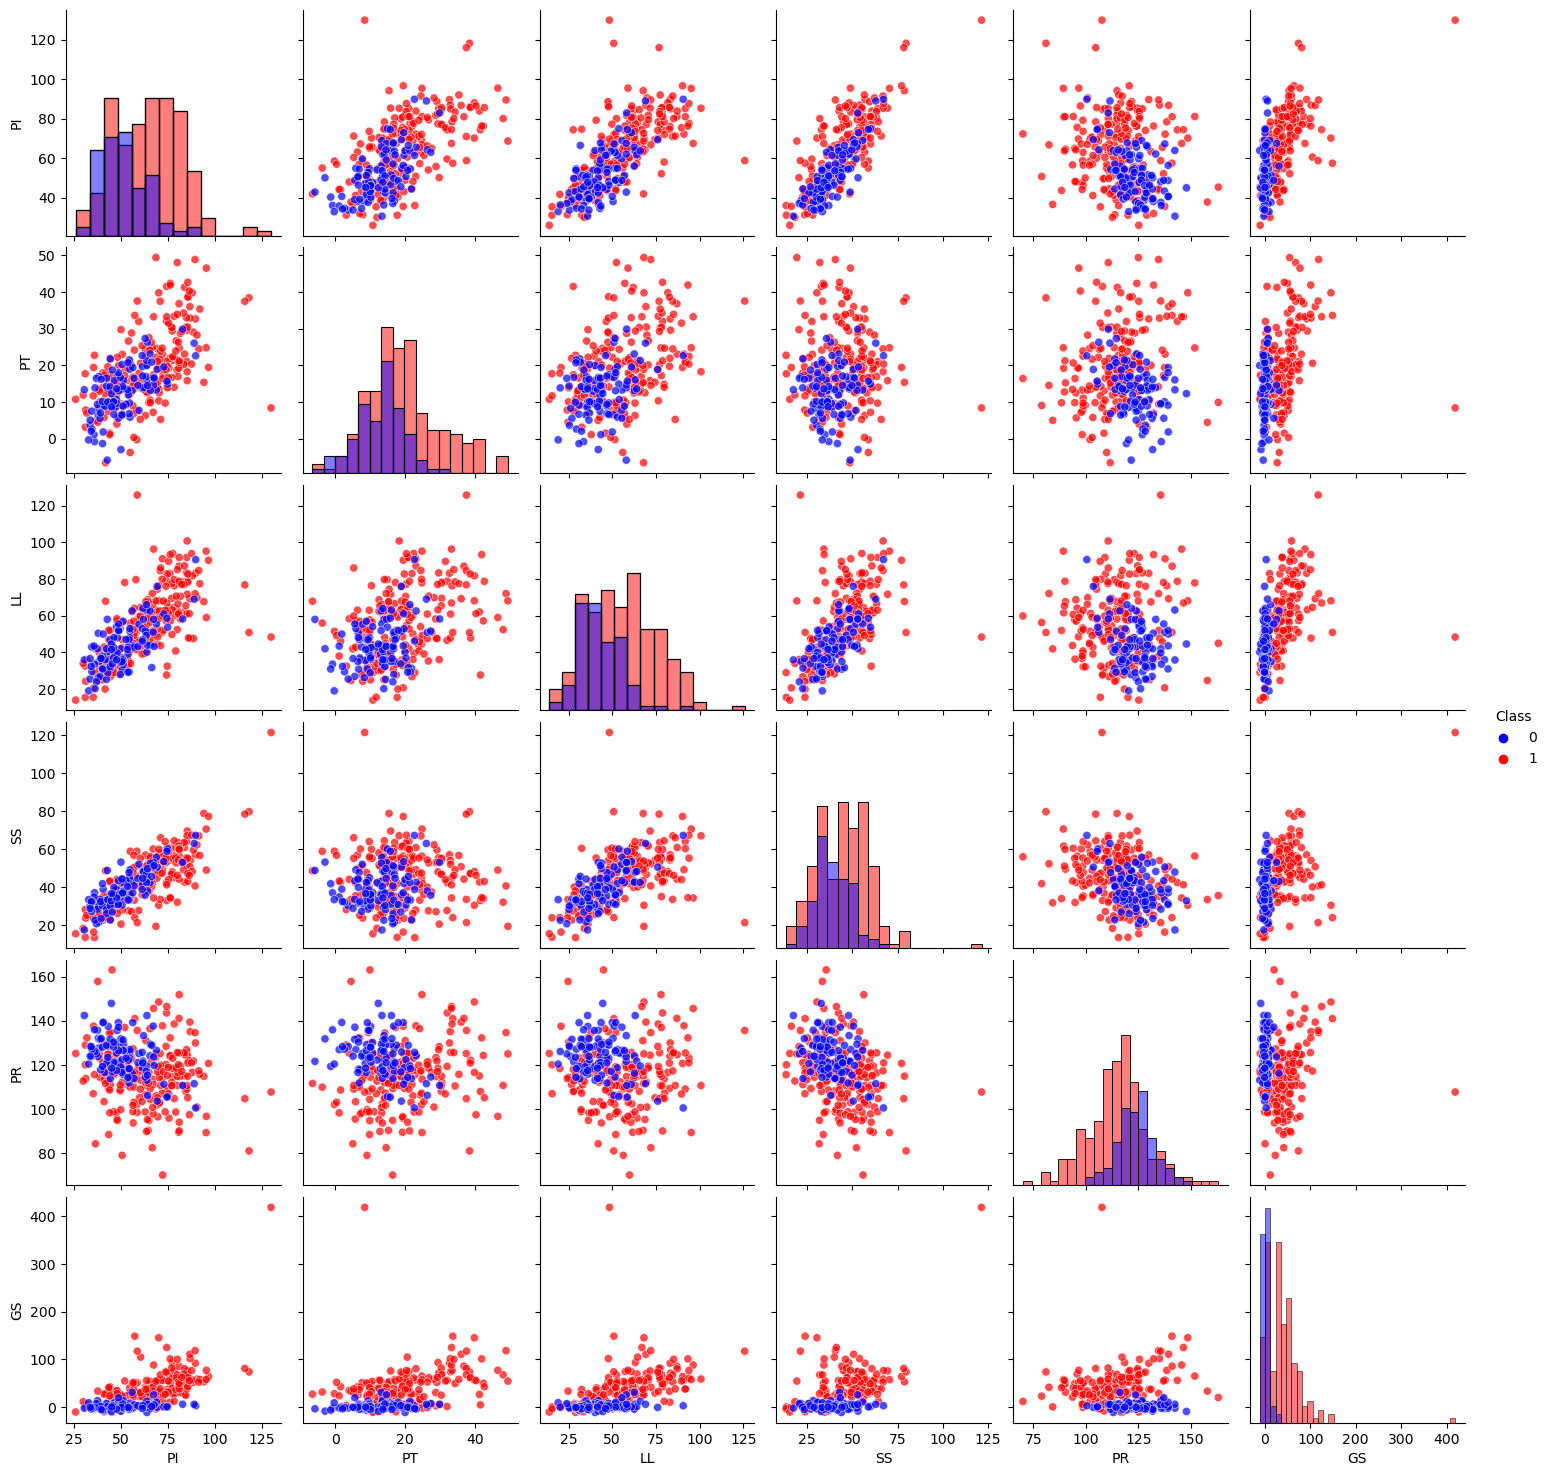

In [3]:
# i
import matplotlib.pyplot as plt
import seaborn as sns

# Define the input features
features = ["PI", "PT", "LL", "SS", "PR", "GS"]

# Create pairwise scatter plots
sns.pairplot(
    df,
    vars=features,
    hue="Class",
    palette={0: "blue", 1: "red"},
    diag_kind="hist",
    plot_kws={"alpha": 0.7, "s": 35}
)

plt.show()

# (ii)  Make boxplots for each of the independent variables

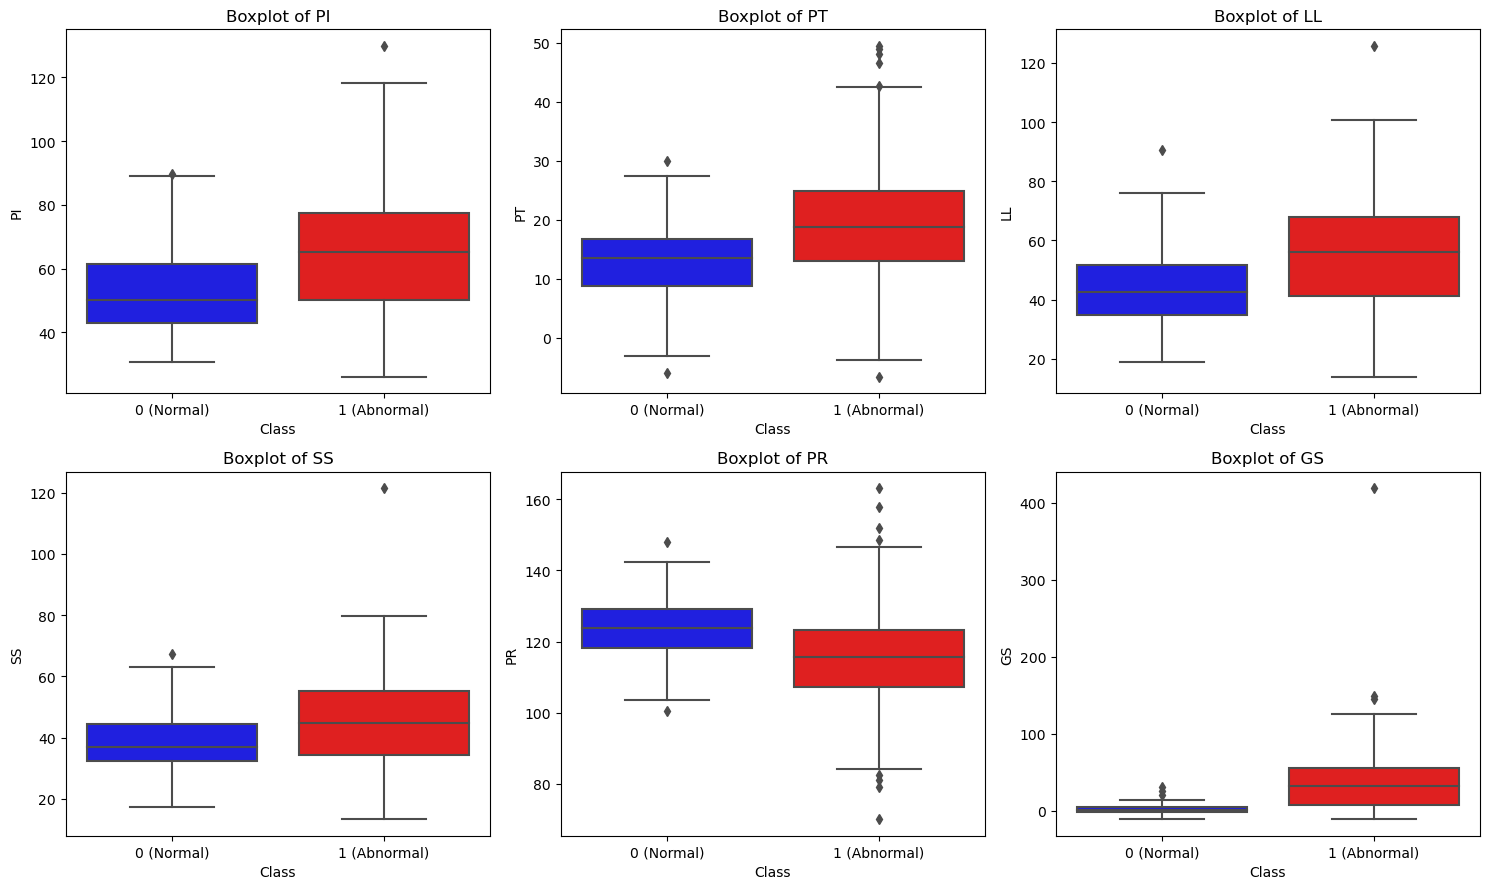

In [4]:
#ii
import matplotlib.pyplot as plt
import seaborn as sns

# Define the input features
features = ["PI", "PT", "LL", "SS", "PR", "GS"]

# Create a 2 × 3 layout
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

# Draw one boxplot for each feature
for feature, ax in zip(features, axes.flatten()):
    sns.boxplot(
        data=df,
        x="Class",
        y=feature,
        palette={0: "blue", 1: "red"},
        ax=ax
    )

    ax.set_title(f"Boxplot of {feature}")
    ax.set_xlabel("Class")
    ax.set_ylabel(feature)
    ax.set_xticklabels(["0 (Normal)", "1 (Abnormal)"])

plt.tight_layout()
plt.show()

# (iii) training set and test set

In [5]:
###iii
import pandas as pd

# Separate the observations by class
class_0 = df[df["Class"] == 0]
class_1 = df[df["Class"] == 1]

# Select the first 70 observations of Class 0
# and the first 140 observations of Class 1
train_class_0 = class_0.iloc[:70]
train_class_1 = class_1.iloc[:140]

# Use the remaining observations as the test set
test_class_0 = class_0.iloc[70:]
test_class_1 = class_1.iloc[140:]

# Combine the observations of both classes
train_df = pd.concat(
    [train_class_0, train_class_1],
    ignore_index=True
)

test_df = pd.concat(
    [test_class_0, test_class_1],
    ignore_index=True
)

# Separate input features and class labels
X_train = train_df[features]
y_train = train_df["Class"]

X_test = test_df[features]
y_test = test_df["Class"]

# Display the results
print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTest class distribution:")
print(y_test.value_counts().sort_index())

Training set shape: (210, 6)
Test set shape: (100, 6)

Training class distribution:
Class
0     70
1    140
Name: count, dtype: int64

Test class distribution:
Class
0    30
1    70
Name: count, dtype: int64


### KNN with Euclidean Distance ( without scaling-with scaling-feature enginnering-LMNN)- extra explanantion
The baseline KNN classifier was first evaluated using all six original variables and Euclidean distance without scaling. Because KNN is a distance-based algorithm, its performance may be affected by feature scales, correlations, and the selected distance metric.

Based on Legaye et al. (1998), pelvic incidence, pelvic tilt, and sacral slope have an important biomechanical relationship. Therefore, the correlations among the variables were examined, and feature engineering was used to evaluate whether removing redundant information could improve classification performance.

Standardization was also examined because the variables have different numerical ranges and measurement interpretations. Without scaling, variables with larger numerical ranges may have a greater influence on Euclidean distance. The scaler was fitted only to the training data and then applied to the test data to avoid information leakage.

LMNN was evaluated as an additional metric-learning method. According to Weinberger and Saul (2009), LMNN learns a transformation of the feature space that attempts to place observations from the same class closer together while separating observations from different classes. However, LMNN does not guarantee better performance for every dataset; therefore, its results were compared with the original KNN model.

Alternative distance metrics were also examined. De Maesschalck et al. (2000) explain that Mahalanobis distance considers the variance and correlation structure of the variables, unlike standard Euclidean distance. Manhattan, Minkowski, Chebyshev, and Mahalanobis distances were therefore compared as required by the assignment.

Finally, distance-weighted KNN was evaluated. In this method, closer neighbors have greater influence than more distant neighbors. This approach follows the distance-weighted nearest-neighbor principle discussed by Dudani (1976).

The main assignment results were obtained using the original features and the required KNN settings. Scaling, feature engineering, and LMNN were included as supplementary analyses.

References
Legaye, J., Duval-Beaupère, G., Hecquet, J., & Marty, C. (1998). Pelvic incidence: A fundamental pelvic parameter for three-dimensional regulation of spinal sagittal curves. European Spine Journal, 7, 99–103.
Weinberger, K. Q., & Saul, L. K. (2009). Distance metric learning for large margin nearest neighbor classification. Journal of Machine Learning Research, 10, 207–244.
De Maesschalck, R., Jouan-Rimbaud, D., & Massart, D. L. (2000). The Mahalanobis distance. Chemometrics and Intelligent Laboratory Systems, 50(1), 1–18.
Dudani, S. A. (1976). The distance-weighted k-nearest-neighbor rule. IEEE Transactions on Systems, Man, and Cybernetics, SMC-6(4), 325–327.

# part (c) , (i)

## KNN without Scaling

In [7]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Set the number of neighbors
k = 5

# Create a KNN classifier with Euclidean distance
knn_without_scaling = KNeighborsClassifier(
    n_neighbors=k,
    metric="euclidean",
    weights="uniform"
)

# Train the model using the original data
knn_without_scaling.fit(X_train, y_train)

# Predict training and test labels
y_train_pred = knn_without_scaling.predict(X_train)
y_test_pred = knn_without_scaling.predict(X_test)

# Calculate accuracy and error rates
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

train_error = 1 - train_accuracy
test_error = 1 - test_accuracy

# Display the results
print("K:", k)
print("Training accuracy:", train_accuracy)
print("Test accuracy:", test_accuracy)
print("Training error rate:", train_error)
print("Test error rate:", test_error)

K: 5
Training accuracy: 0.8523809523809524
Test accuracy: 0.9
Training error rate: 0.14761904761904765
Test error rate: 0.09999999999999998


KNN Without scaling
For \(k=5\), the KNN model achieved a training accuracy of 85.24% and a test accuracy of 90%. The corresponding training and test error rates were 14.76% and 10%, respectively. The slightly better test performance suggests that the model generalizes reasonably well and shows no clear evidence of overfitting.

### KNN with Scaling ( extra)

In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Set the number of neighbors
k = 5

# Standardize the input features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Create a KNN classifier with Euclidean distance
knn_with_scaling = KNeighborsClassifier(
    n_neighbors=k,
    metric="euclidean",
    weights="uniform"
)

# Train the model using the scaled training data
knn_with_scaling.fit(X_train_scaled, y_train)

# Predict training and test labels
y_train_pred_scaled = knn_with_scaling.predict(X_train_scaled)
y_test_pred_scaled = knn_with_scaling.predict(X_test_scaled)

# Calculate accuracy and error rates
train_accuracy_scaled = accuracy_score(
    y_train,
    y_train_pred_scaled
)

test_accuracy_scaled = accuracy_score(
    y_test,
    y_test_pred_scaled
)

train_error_scaled = 1 - train_accuracy_scaled
test_error_scaled = 1 - test_accuracy_scaled

# Display the results
print("K:", k)
print("Training accuracy:", train_accuracy_scaled)
print("Test accuracy:", test_accuracy_scaled)
print("Training error rate:", train_error_scaled)
print("Test error rate:", test_error_scaled)

K: 5
Training accuracy: 0.8714285714285714
Test accuracy: 0.82
Training error rate: 0.12857142857142856
Test error rate: 0.18000000000000005


In [ ]:
KNN With Scaling
For \(k=5\), the KNN model achieved a training accuracy of 87.14% and a test accuracy of 82%. 
The test error rate of 18% is higher than the training error rate of 12.86%, indicating a moderate decline in performance on unseen data and some degree of overfitting.

Evaluation Across All Values of (k)
In this section, all values of (k) specified in the assignment were evaluated under two preprocessing conditions: with feature scaling and without feature scaling. The USE_SCALING variable controls which condition is applied. When USE_SCALING = False, the KNN models are fitted using the original, unscaled feature values. When USE_SCALING = True, the features are standardized before fitting the models. This comparison helps determine whether scaling improves KNN classification performance.

# Part(c) , (ii) knn without scaling
USE_SCALING = False

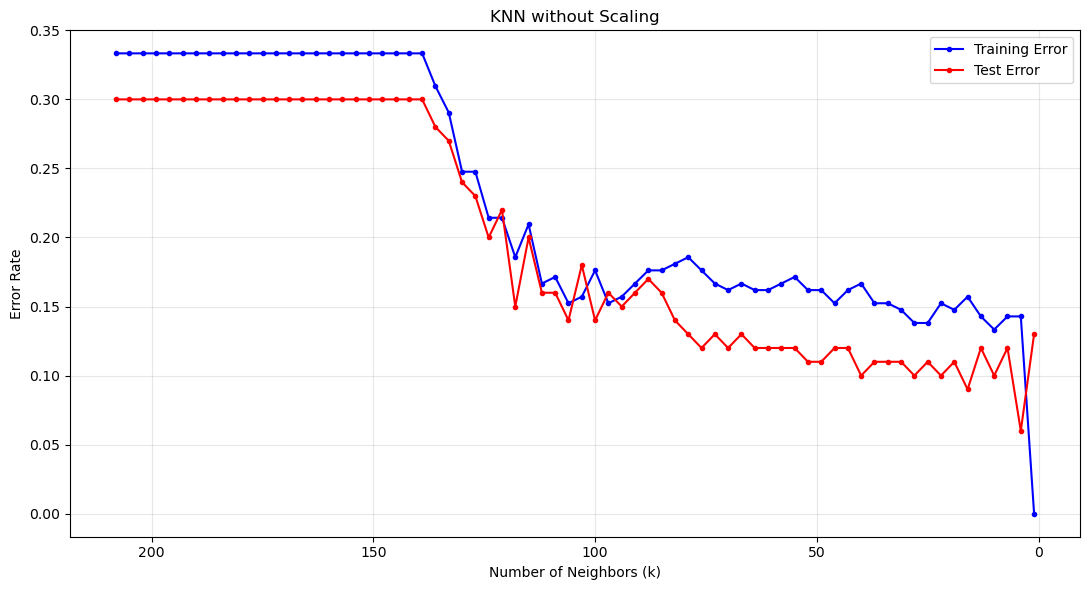

Model: KNN without Scaling
Best k values: [4]
Selected k*: 4
Minimum test error: 0.06

Confusion Matrix:
[[25  5]
 [ 1 69]]

TN: 25
FP: 5
FN: 1
TP: 69

True Positive Rate: 0.9857142857142858
True Negative Rate: 0.8333333333333334
Precision: 0.9324324324324325
F1-score: 0.9583333333333333


In [9]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn import set_config
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    f1_score
)

# ---------------------------------------------------------
# Avoid the threadpoolctl/OpenBLAS compatibility problem
# ---------------------------------------------------------
try:
    set_config(enable_cython_pairwise_dist=False)
except TypeError:
    pass

# ---------------------------------------------------------
# Select preprocessing mode
# False: without scaling
# True: with StandardScaler
# ---------------------------------------------------------
USE_SCALING = False

# ---------------------------------------------------------
# Convert data to NumPy arrays
# ---------------------------------------------------------
X_train_array = np.asarray(
    X_train,
    dtype=np.float64,
    order="C"
)

X_test_array = np.asarray(
    X_test,
    dtype=np.float64,
    order="C"
)

y_train_array = np.asarray(
    y_train,
    dtype=int
).ravel()

y_test_array = np.asarray(
    y_test,
    dtype=int
).ravel()

# ---------------------------------------------------------
# Apply scaling if requested
# ---------------------------------------------------------
if USE_SCALING:
    scaler = StandardScaler()

    # Fit the scaler only on training data
    X_train_model = scaler.fit_transform(X_train_array)
    X_test_model = scaler.transform(X_test_array)

    model_name = "KNN with Scaling"
else:
    X_train_model = X_train_array.copy()
    X_test_model = X_test_array.copy()

    model_name = "KNN without Scaling"

# ---------------------------------------------------------
# Validate the input data
# ---------------------------------------------------------
if np.isnan(X_train_model).any():
    raise ValueError("X_train contains missing values.")

if np.isnan(X_test_model).any():
    raise ValueError("X_test contains missing values.")

if len(X_train_model) != len(y_train_array):
    raise ValueError("X_train and y_train have different sizes.")

if len(X_test_model) != len(y_test_array):
    raise ValueError("X_test and y_test have different sizes.")

# ---------------------------------------------------------
# Define k values: 208, 205, ..., 7, 4, 1
# ---------------------------------------------------------
k_values = list(range(208, 0, -3))

# Keep only valid values of k
k_values = [
    k for k in k_values
    if k <= len(X_train_model)
]

train_errors = []
test_errors = []

# ---------------------------------------------------------
# Evaluate KNN for every k
# ---------------------------------------------------------
for k in k_values:
    knn = KNeighborsClassifier(
        n_neighbors=k,
        metric="euclidean",
        weights="uniform",
        algorithm="kd_tree"
    )

    # Train the model
    knn.fit(
        X_train_model,
        y_train_array
    )

    # Predict labels
    train_predictions = knn.predict(
        X_train_model
    )

    test_predictions = knn.predict(
        X_test_model
    )

    # Calculate error rates
    train_error = np.mean(
        train_predictions != y_train_array
    )

    test_error = np.mean(
        test_predictions != y_test_array
    )

    train_errors.append(train_error)
    test_errors.append(test_error)

# ---------------------------------------------------------
# Plot training and test errors
# ---------------------------------------------------------
plt.figure(figsize=(11, 6))

plt.plot(
    k_values,
    train_errors,
    color="blue",
    marker="o",
    markersize=3,
    label="Training Error"
)

plt.plot(
    k_values,
    test_errors,
    color="red",
    marker="o",
    markersize=3,
    label="Test Error"
)

# Show k values from large to small
plt.gca().invert_xaxis()

plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Error Rate")
plt.title(model_name)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Find the optimal k
# ---------------------------------------------------------
minimum_test_error = min(test_errors)

best_k_values = [
    k
    for k, error in zip(k_values, test_errors)
    if np.isclose(error, minimum_test_error)
]

# Use the largest k when several values have the same error
k_star = max(best_k_values)

# ---------------------------------------------------------
# Train the final model using k*
# ---------------------------------------------------------
final_knn = KNeighborsClassifier(
    n_neighbors=k_star,
    metric="euclidean",
    weights="uniform",
    algorithm="kd_tree"
)

final_knn.fit(
    X_train_model,
    y_train_array
)

y_test_pred = final_knn.predict(
    X_test_model
)

# ---------------------------------------------------------
# Calculate the confusion matrix
# ---------------------------------------------------------
cm = confusion_matrix(
    y_test_array,
    y_test_pred,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

# ---------------------------------------------------------
# Calculate evaluation metrics
# ---------------------------------------------------------
true_positive_rate = (
    tp / (tp + fn)
    if (tp + fn) > 0
    else 0
)

true_negative_rate = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else 0
)

precision = precision_score(
    y_test_array,
    y_test_pred,
    pos_label=1,
    zero_division=0
)

f1 = f1_score(
    y_test_array,
    y_test_pred,
    pos_label=1,
    zero_division=0
)

# ---------------------------------------------------------
# Display the final results
# ---------------------------------------------------------
print("Model:", model_name)
print("Best k values:", best_k_values)
print("Selected k*:", k_star)
print("Minimum test error:", minimum_test_error)

print("\nConfusion Matrix:")
print(cm)

print("\nTN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

print("\nTrue Positive Rate:", true_positive_rate)
print("True Negative Rate:", true_negative_rate)
print("Precision:", precision)
print("F1-score:", f1)

The unscaled KNN model achieved its best performance at \(k=4\), with a minimum test error of 6% and a test accuracy of 94%. It correctly classified 69 of 70 abnormal cases and 25 of 30 normal cases. The high TPR (98.57%), precision (93.24%), and F1-score (95.83%) indicate excellent detection of abnormal cases, although the lower TNR (83.33%) shows slightly weaker identification of normal cases.

### part (c) , (ii) ,  KNN With scaling- extra
USE_SCALING = Ture

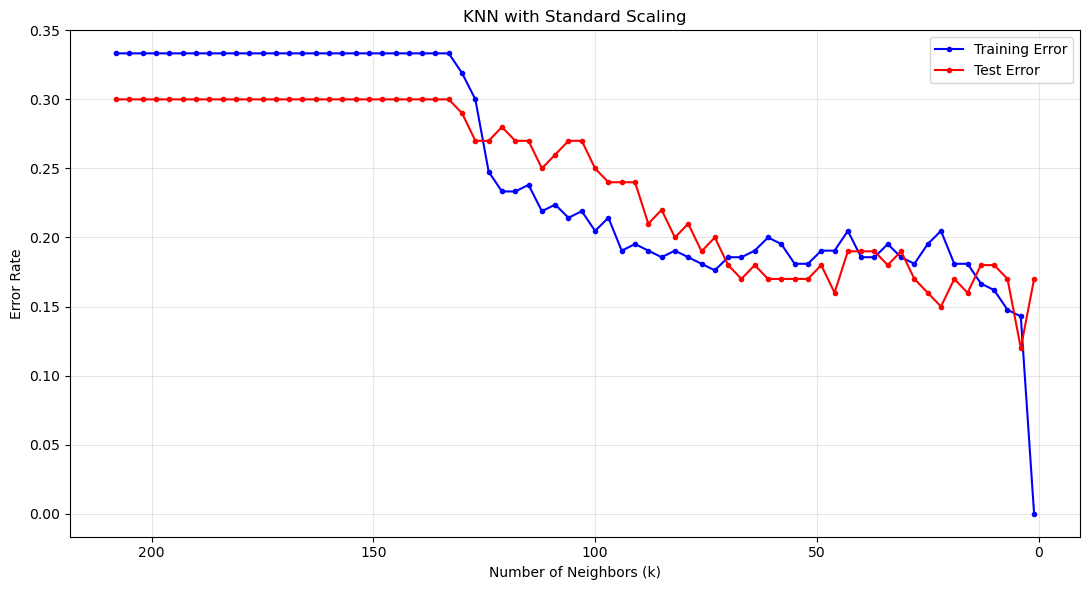

Model: KNN with Standard Scaling
Best k values: [4]
Selected k*: 4
Minimum test error: 0.12

Confusion Matrix:
[[22  8]
 [ 4 66]]

TN: 22
FP: 8
FN: 4
TP: 66

True Positive Rate: 0.9428571428571428
True Negative Rate: 0.7333333333333333
Precision: 0.8918918918918919
F1-score: 0.9166666666666667


In [10]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn import set_config
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    f1_score
)

# Avoid the threadpoolctl/OpenBLAS compatibility problem
try:
    set_config(enable_cython_pairwise_dist=False)
except TypeError:
    pass

# Convert data to NumPy arrays
X_train_array = np.asarray(
    X_train,
    dtype=np.float64,
    order="C"
)

X_test_array = np.asarray(
    X_test,
    dtype=np.float64,
    order="C"
)

y_train_array = np.asarray(
    y_train,
    dtype=int
).ravel()

y_test_array = np.asarray(
    y_test,
    dtype=int
).ravel()

# Check for missing values
if np.isnan(X_train_array).any():
    raise ValueError("X_train contains missing values.")

if np.isnan(X_test_array).any():
    raise ValueError("X_test contains missing values.")

# Standardize the input features
scaler = StandardScaler()

# Fit only on the training data
X_train_scaled = scaler.fit_transform(X_train_array)

# Apply the same transformation to test data
X_test_scaled = scaler.transform(X_test_array)

# Define k values: 208, 205, ..., 7, 4, 1
k_values = list(range(208, 0, -3))

# Keep only valid values of k
k_values = [
    k for k in k_values
    if k <= len(X_train_scaled)
]

train_errors = []
test_errors = []

# Evaluate KNN for every k
for k in k_values:
    knn = KNeighborsClassifier(
        n_neighbors=k,
        metric="euclidean",
        weights="uniform",
        algorithm="kd_tree"
    )

    # Train the model
    knn.fit(
        X_train_scaled,
        y_train_array
    )

    # Predict training and test labels
    train_predictions = knn.predict(
        X_train_scaled
    )

    test_predictions = knn.predict(
        X_test_scaled
    )

    # Calculate error rates
    train_error = np.mean(
        train_predictions != y_train_array
    )

    test_error = np.mean(
        test_predictions != y_test_array
    )

    train_errors.append(train_error)
    test_errors.append(test_error)

# Plot training and test errors
plt.figure(figsize=(11, 6))

plt.plot(
    k_values,
    train_errors,
    color="blue",
    marker="o",
    markersize=3,
    label="Training Error"
)

plt.plot(
    k_values,
    test_errors,
    color="red",
    marker="o",
    markersize=3,
    label="Test Error"
)

# Display k values from 208 to 1
plt.gca().invert_xaxis()

plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Error Rate")
plt.title("KNN with Standard Scaling")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Find the minimum test error
minimum_test_error = min(test_errors)

# Find all k values with the minimum test error
best_k_values = [
    k
    for k, error in zip(k_values, test_errors)
    if np.isclose(error, minimum_test_error)
]

# Select the largest k in case of a tie
k_star = max(best_k_values)

# Train the final model using k*
final_knn = KNeighborsClassifier(
    n_neighbors=k_star,
    metric="euclidean",
    weights="uniform",
    algorithm="kd_tree"
)

final_knn.fit(
    X_train_scaled,
    y_train_array
)

# Predict test labels
y_test_pred = final_knn.predict(
    X_test_scaled
)

# Calculate the confusion matrix
cm = confusion_matrix(
    y_test_array,
    y_test_pred,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

# Calculate the requested metrics
true_positive_rate = (
    tp / (tp + fn)
    if (tp + fn) > 0
    else 0
)

true_negative_rate = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else 0
)

precision = precision_score(
    y_test_array,
    y_test_pred,
    pos_label=1,
    zero_division=0
)

f1 = f1_score(
    y_test_array,
    y_test_pred,
    pos_label=1,
    zero_division=0
)

# Display the final results
print("Model: KNN with Standard Scaling")
print("Best k values:", best_k_values)
print("Selected k*:", k_star)
print("Minimum test error:", minimum_test_error)

print("\nConfusion Matrix:")
print(cm)

print("\nTN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

print("\nTrue Positive Rate:", true_positive_rate)
print("True Negative Rate:", true_negative_rate)
print("Precision:", precision)
print("F1-score:", f1)

In [ ]:
The scaled KNN model achieved its best performance at \(k=4\), with a test error of 12% and an accuracy of 88%. It correctly identified 66 of 70 abnormal cases and 22 of 30 normal cases. 
Compared with the unscaled model, scaling reduced performance across all evaluation measures; therefore, KNN without scaling was more suitable for this dataset.

### Feature Engineering Based on Correlations Among Variables- extra

After examining the correlation matrix, I observed strong relationships among some of the biomechanical variables. This suggested that feature engineering could be used to reduce redundant information and evaluate whether a simpler feature space improves KNN performance.

The analysis confirmed that Pelvic Incidence is approximately equal to the sum of Pelvic Tilt and Sacral Slope:

PI ≈ PT + SS

Therefore, these three variables contain overlapping information. Because PI can be derived from PT and SS, PI was removed while PT and SS were retained. No additional combined feature was created because PI already represents their combination.

The reduced feature set was:

{PT, LL, SS, PR, GS}

The KNN classifier was then rerun with this reduced feature set, both with and without standardization, to determine whether removing redundant information and applying feature scaling could improve classification performance.

Correlation Matrix:


,PI,PT,LL,SS,PR,GS
PI,1.000,0.629,0.717,0.815,-0.247,0.639
PT,0.629,1.000,0.433,0.062,0.033,0.398
LL,0.717,0.433,1.000,0.598,-0.080,0.534
SS,0.815,0.062,0.598,1.000,-0.342,0.524
PR,-0.247,0.033,-0.080,-0.342,1.000,-0.026
GS,0.639,0.398,0.534,0.524,-0.026,1.000


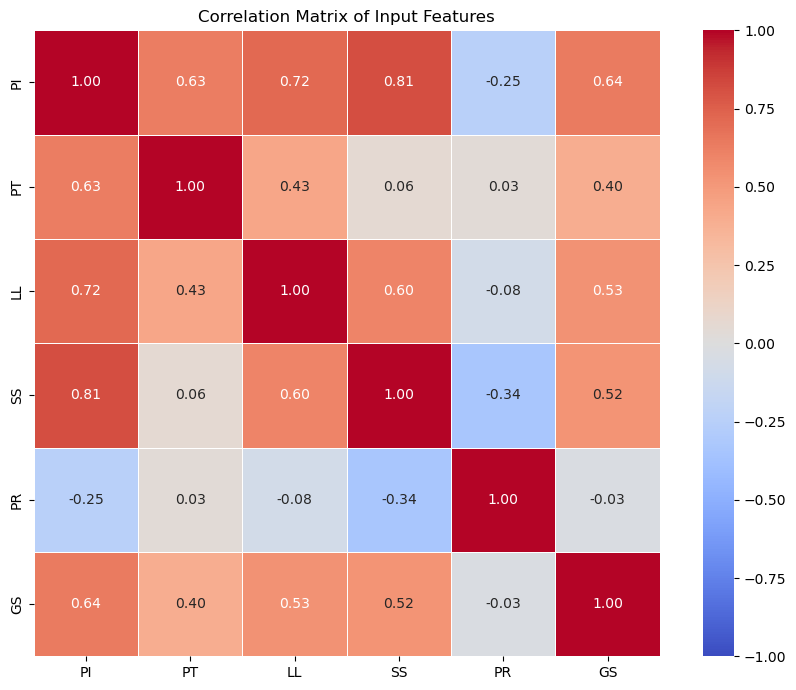


Highly Correlated Feature Pairs:


,Feature 1,Feature 2,Correlation
1,PI,SS,0.815
0,PI,LL,0.717



Verification of PI = PT + SS:
Maximum absolute difference: 0.010000000000005116
Mean absolute difference: 0.0028709677419368035

Small differences exist because of rounding or measurement error.

Candidate Feature Sets:
All Features: ['PI', 'PT', 'LL', 'SS', 'PR', 'GS']
Without PI: ['PT', 'LL', 'SS', 'PR', 'GS']
Without PT: ['PI', 'LL', 'SS', 'PR', 'GS']
Without SS: ['PI', 'PT', 'LL', 'PR', 'GS']


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Define input features
features = ["PI", "PT", "LL", "SS", "PR", "GS"]

# ---------------------------------------------------------
# 1. Calculate the Pearson correlation matrix
# ---------------------------------------------------------
correlation_matrix = df[features].corr(
    method="pearson"
)

print("Correlation Matrix:")
display(correlation_matrix.round(3))

# ---------------------------------------------------------
# 2. Plot the correlation heatmap
# ---------------------------------------------------------
plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5
)

plt.title("Correlation Matrix of Input Features")
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 3. Find highly correlated feature pairs
# ---------------------------------------------------------
threshold = 0.70
high_correlations = []

for i in range(len(features)):
    for j in range(i + 1, len(features)):
        feature_1 = features[i]
        feature_2 = features[j]

        correlation = correlation_matrix.loc[
            feature_1,
            feature_2
        ]

        if abs(correlation) >= threshold:
            high_correlations.append({
                "Feature 1": feature_1,
                "Feature 2": feature_2,
                "Correlation": correlation,
                "Absolute Correlation": abs(correlation)
            })

high_correlation_df = pd.DataFrame(
    high_correlations
)

print("\nHighly Correlated Feature Pairs:")

if high_correlation_df.empty:
    print("No feature pairs exceeded the threshold.")
else:
    high_correlation_df = high_correlation_df.sort_values(
        by="Absolute Correlation",
        ascending=False
    )

    display(
        high_correlation_df[
            ["Feature 1", "Feature 2", "Correlation"]
        ].round(3)
    )

# ---------------------------------------------------------
# 4. Verify the geometric relationship
# PI = PT + SS
# ---------------------------------------------------------
geometric_difference = (
    df["PI"] - (df["PT"] + df["SS"])
)

maximum_difference = np.abs(
    geometric_difference
).max()

mean_difference = np.abs(
    geometric_difference
).mean()

print("\nVerification of PI = PT + SS:")
print(
    "Maximum absolute difference:",
    maximum_difference
)
print(
    "Mean absolute difference:",
    mean_difference
)

# ---------------------------------------------------------
# 5. Interpret the geometric relationship
# ---------------------------------------------------------
tolerance = 0.01

if maximum_difference <= tolerance:
    print(
        "\nPI = PT + SS is verified within the tolerance."
    )
    print(
        "PI, PT, and SS contain redundant information."
    )
else:
    print(
        "\nSmall differences exist because of rounding "
        "or measurement error."
    )

# ---------------------------------------------------------
# 6. Define candidate feature sets
# ---------------------------------------------------------
feature_sets = {
    "All Features": [
        "PI", "PT", "LL", "SS", "PR", "GS"
    ],

    "Without PI": [
        "PT", "LL", "SS", "PR", "GS"
    ],

    "Without PT": [
        "PI", "LL", "SS", "PR", "GS"
    ],

    "Without SS": [
        "PI", "PT", "LL", "PR", "GS"
    ]
}

print("\nCandidate Feature Sets:")

for name, selected_features in feature_sets.items():
    print(f"{name}: {selected_features}")

## Compare KNN without scaling and  KNN with scaling- extra

Removed feature: PI
Selected features: ['PT', 'LL', 'SS', 'PR', 'GS']
Number of evaluated k values: 70
Evaluated k values:
[208, 205, 202, 199, 196, 193, 190, 187, 184, 181, 178, 175, 172, 169, 166, 163, 160, 157, 154, 151, 148, 145, 142, 139, 136, 133, 130, 127, 124, 121, 118, 115, 112, 109, 106, 103, 100, 97, 94, 91, 88, 85, 82, 79, 76, 73, 70, 67, 64, 61, 58, 55, 52, 49, 46, 43, 40, 37, 34, 31, 28, 25, 22, 19, 16, 13, 10, 7, 4, 1]


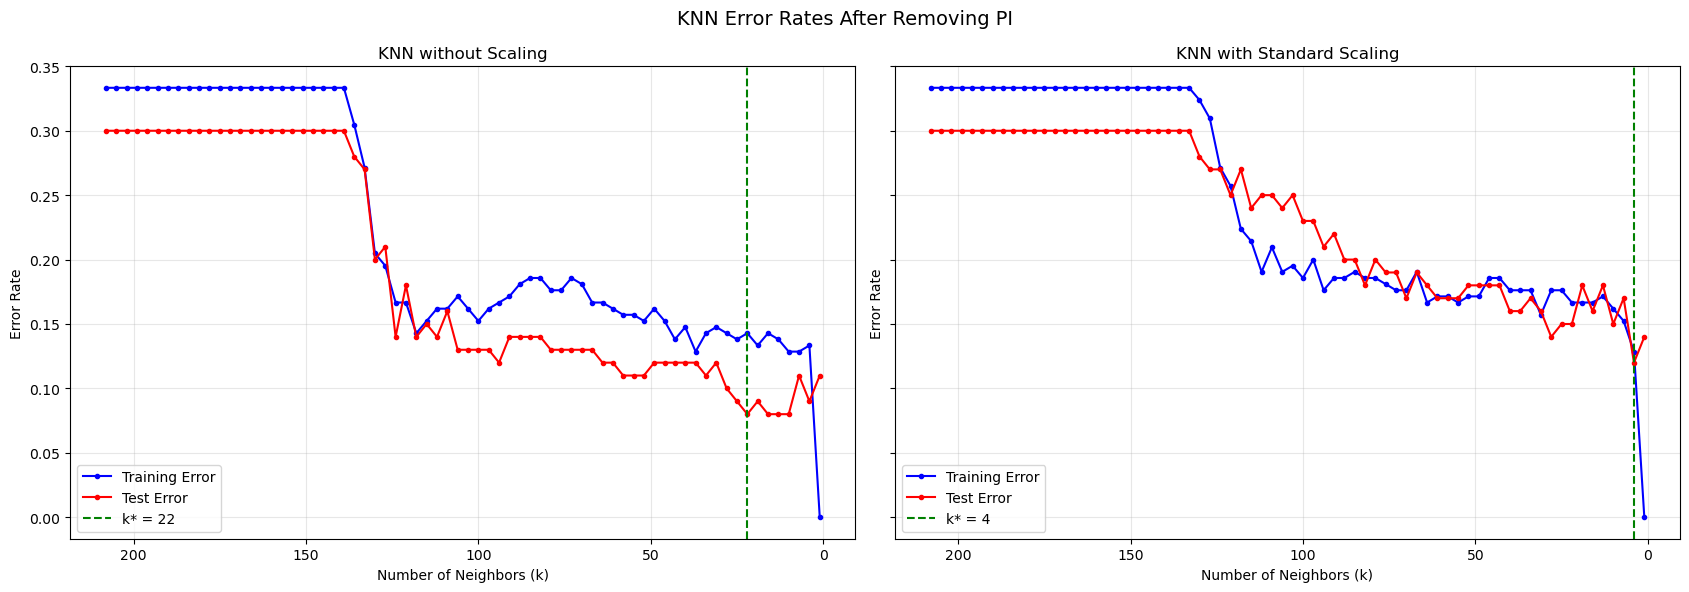


Model: KNN without Scaling
Features: ['PT', 'LL', 'SS', 'PR', 'GS']
Best k values: [22, 16, 13, 10]
Selected k*: 22
Training error: 0.14285714285714285
Test error: 0.08
Test accuracy: 0.92

Confusion Matrix:
[[23  7]
 [ 1 69]]

TN: 23
FP: 7
FN: 1
TP: 69

True Positive Rate: 0.9857142857142858
True Negative Rate: 0.7666666666666667
Precision: 0.9078947368421053
F1-score: 0.9452054794520548

Model: KNN with Standard Scaling
Features: ['PT', 'LL', 'SS', 'PR', 'GS']
Best k values: [4]
Selected k*: 4
Training error: 0.12857142857142856
Test error: 0.12
Test accuracy: 0.88

Confusion Matrix:
[[22  8]
 [ 4 66]]

TN: 22
FP: 8
FN: 4
TP: 66

True Positive Rate: 0.9428571428571428
True Negative Rate: 0.7333333333333333
Precision: 0.8918918918918919
F1-score: 0.9166666666666667

Final Comparison After Removing PI:


,Model,Removed Feature,k*,Training Error,Test Error,Test Accuracy,TPR,TNR,Precision,F1-score
0,KNN without Scaling,PI,22,0.1429,0.08,0.92,0.9857,0.7667,0.9079,0.9452
1,KNN with Standard Scaling,PI,4,0.1286,0.12,0.88,0.9429,0.7333,0.8919,0.9167


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn import set_config
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    f1_score
)

# Avoid the threadpoolctl/OpenBLAS compatibility problem
try:
    set_config(enable_cython_pairwise_dist=False)
except TypeError:
    pass

# ---------------------------------------------------------
# 1. Feature selection
# PI is removed because PI is approximately PT + SS
# ---------------------------------------------------------
selected_features = [
    "PT",
    "LL",
    "SS",
    "PR",
    "GS"
]

print("Removed feature: PI")
print("Selected features:", selected_features)

# ---------------------------------------------------------
# 2. Prepare training and test data
# ---------------------------------------------------------
X_train_reduced = np.asarray(
    train_df[selected_features],
    dtype=np.float64,
    order="C"
)

X_test_reduced = np.asarray(
    test_df[selected_features],
    dtype=np.float64,
    order="C"
)

y_train_array = np.asarray(
    train_df["Class"],
    dtype=int
).ravel()

y_test_array = np.asarray(
    test_df["Class"],
    dtype=int
).ravel()

# Check the data dimensions
if len(X_train_reduced) != len(y_train_array):
    raise ValueError(
        "X_train and y_train have different sizes."
    )

if len(X_test_reduced) != len(y_test_array):
    raise ValueError(
        "X_test and y_test have different sizes."
    )

# Check for missing values
if np.isnan(X_train_reduced).any():
    raise ValueError(
        "Training features contain missing values."
    )

if np.isnan(X_test_reduced).any():
    raise ValueError(
        "Test features contain missing values."
    )

# ---------------------------------------------------------
# 3. Define all requested k values
# 208, 205, ..., 7, 4, 1
# ---------------------------------------------------------
k_values = list(range(208, 0, -3))

# Keep only valid values
k_values = [
    k
    for k in k_values
    if k <= len(X_train_reduced)
]

print("Number of evaluated k values:", len(k_values))
print("Evaluated k values:")
print(k_values)

# ---------------------------------------------------------
# 4. Define the KNN evaluation function
# ---------------------------------------------------------
def run_knn(use_scaling=False):

    # Prepare data for the selected mode
    if use_scaling:
        scaler = StandardScaler()

        # Fit only on the training data
        X_train_model = scaler.fit_transform(
            X_train_reduced
        )

        X_test_model = scaler.transform(
            X_test_reduced
        )

        model_name = "KNN with Standard Scaling"

    else:
        X_train_model = X_train_reduced.copy()
        X_test_model = X_test_reduced.copy()

        model_name = "KNN without Scaling"

    # Ensure contiguous NumPy arrays
    X_train_model = np.ascontiguousarray(
        X_train_model,
        dtype=np.float64
    )

    X_test_model = np.ascontiguousarray(
        X_test_model,
        dtype=np.float64
    )

    train_errors = []
    test_errors = []

    # Evaluate every requested k
    for k in k_values:

        knn = KNeighborsClassifier(
            n_neighbors=k,
            metric="euclidean",
            weights="uniform",
            algorithm="kd_tree"
        )

        # Train the model
        knn.fit(
            X_train_model,
            y_train_array
        )

        # Predict training and test labels
        train_predictions = knn.predict(
            X_train_model
        )

        test_predictions = knn.predict(
            X_test_model
        )

        # Calculate error rates
        train_error = np.mean(
            train_predictions != y_train_array
        )

        test_error = np.mean(
            test_predictions != y_test_array
        )

        train_errors.append(train_error)
        test_errors.append(test_error)

    # Find the minimum test error
    minimum_test_error = min(test_errors)

    # Find all k values with minimum test error
    best_k_values = [
        k
        for k, error in zip(k_values, test_errors)
        if np.isclose(error, minimum_test_error)
    ]

    # Select the largest k in case of a tie
    k_star = max(best_k_values)

    # Train the final model using k*
    final_model = KNeighborsClassifier(
        n_neighbors=k_star,
        metric="euclidean",
        weights="uniform",
        algorithm="kd_tree"
    )

    final_model.fit(
        X_train_model,
        y_train_array
    )

    # Final predictions
    final_train_predictions = final_model.predict(
        X_train_model
    )

    final_test_predictions = final_model.predict(
        X_test_model
    )

    # Final error rates
    final_train_error = np.mean(
        final_train_predictions != y_train_array
    )

    final_test_error = np.mean(
        final_test_predictions != y_test_array
    )

    # Confusion matrix
    cm = confusion_matrix(
        y_test_array,
        final_test_predictions,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    # Evaluation metrics
    test_accuracy = np.mean(
        final_test_predictions == y_test_array
    )

    true_positive_rate = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0
    )

    true_negative_rate = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0
    )

    precision = precision_score(
        y_test_array,
        final_test_predictions,
        pos_label=1,
        zero_division=0
    )

    f1 = f1_score(
        y_test_array,
        final_test_predictions,
        pos_label=1,
        zero_division=0
    )

    return {
        "Model": model_name,
        "Train Errors": train_errors,
        "Test Errors": test_errors,
        "Best k Values": best_k_values,
        "k*": k_star,
        "Training Error": final_train_error,
        "Test Error": final_test_error,
        "Test Accuracy": test_accuracy,
        "Confusion Matrix": cm,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "TPR": true_positive_rate,
        "TNR": true_negative_rate,
        "Precision": precision,
        "F1-score": f1
    }

# ---------------------------------------------------------
# 5. Run KNN in both modes
# ---------------------------------------------------------
result_without_scaling = run_knn(
    use_scaling=False
)

result_with_scaling = run_knn(
    use_scaling=True
)

results = [
    result_without_scaling,
    result_with_scaling
]

# ---------------------------------------------------------
# 6. Plot error curves for both modes
# ---------------------------------------------------------
fig, axes = plt.subplots(
    1,
    2,
    figsize=(17, 6),
    sharey=True
)

for ax, result in zip(axes, results):

    ax.plot(
        k_values,
        result["Train Errors"],
        color="blue",
        marker="o",
        markersize=3,
        label="Training Error"
    )

    ax.plot(
        k_values,
        result["Test Errors"],
        color="red",
        marker="o",
        markersize=3,
        label="Test Error"
    )

    # Mark the selected k*
    ax.axvline(
        result["k*"],
        color="green",
        linestyle="--",
        label=f'k* = {result["k*"]}'
    )

    # Display k values in reverse order
    ax.invert_xaxis()

    ax.set_title(result["Model"])
    ax.set_xlabel("Number of Neighbors (k)")
    ax.set_ylabel("Error Rate")
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle(
    "KNN Error Rates After Removing PI",
    fontsize=14
)

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 7. Display detailed results
# ---------------------------------------------------------
for result in results:

    print("\n" + "=" * 50)
    print("Model:", result["Model"])
    print("Features:", selected_features)
    print("Best k values:", result["Best k Values"])
    print("Selected k*:", result["k*"])
    print("Training error:", result["Training Error"])
    print("Test error:", result["Test Error"])
    print("Test accuracy:", result["Test Accuracy"])

    print("\nConfusion Matrix:")
    print(result["Confusion Matrix"])

    print("\nTN:", result["TN"])
    print("FP:", result["FP"])
    print("FN:", result["FN"])
    print("TP:", result["TP"])

    print("\nTrue Positive Rate:", result["TPR"])
    print("True Negative Rate:", result["TNR"])
    print("Precision:", result["Precision"])
    print("F1-score:", result["F1-score"])

# ---------------------------------------------------------
# 8. Create the final comparison table
# ---------------------------------------------------------
comparison_table = pd.DataFrame({
    "Model": [
        result_without_scaling["Model"],
        result_with_scaling["Model"]
    ],
    "Removed Feature": [
        "PI",
        "PI"
    ],
    "k*": [
        result_without_scaling["k*"],
        result_with_scaling["k*"]
    ],
    "Training Error": [
        result_without_scaling["Training Error"],
        result_with_scaling["Training Error"]
    ],
    "Test Error": [
        result_without_scaling["Test Error"],
        result_with_scaling["Test Error"]
    ],
    "Test Accuracy": [
        result_without_scaling["Test Accuracy"],
        result_with_scaling["Test Accuracy"]
    ],
    "TPR": [
        result_without_scaling["TPR"],
        result_with_scaling["TPR"]
    ],
    "TNR": [
        result_without_scaling["TNR"],
        result_with_scaling["TNR"]
    ],
    "Precision": [
        result_without_scaling["Precision"],
        result_with_scaling["Precision"]
    ],
    "F1-score": [
        result_without_scaling["F1-score"],
        result_with_scaling["F1-score"]
    ]
})

print("\nFinal Comparison After Removing PI:")
display(comparison_table.round(4))

Interpretation After Removing PI

KNN without Scaling: After removing PI, the unscaled model achieved its best performance at (k=22), with 92% test accuracy and an F1-score of 94.52%. Its high TPR of 98.57% indicates excellent identification of abnormal cases.

KNN with Standard Scaling: The scaled model performed best at (k=4), achieving 88% test accuracy and an F1-score of 91.67%. Its higher test error and lower evaluation metrics indicate weaker performance.

Comparison: After feature engineering, the unscaled KNN model outperformed the scaled model; therefore, scaling did not improve classification performance on the reduced feature set.

### X⟶LMNN⟶KNN ( extra)
In this stage, LMNN was used as a supervised preprocessing and distance-metric learning method before applying KNN. LMNN transforms the feature space so that observations from the same class tend to become closer, while observations from different classes become more separated. The transformed data were then used as input to the KNN classifier. The pipeline above illustrates the sequence of this analysis.

#### Installing the LMNN Package

To use LMNN in the Jupyter Notebook, the metric-learn library was installed using the following command

In [13]:
%pip install metric-learn

Note: you may need to restart the kernel to use updated packages.


Dataset shape: (310, 7)

Class distribution:
Class
0    100
1    210
Name: count, dtype: int64

Training set shape: (210, 7)
Test set shape: (100, 7)

Training class distribution:
Class
0     70
1    140
Name: count, dtype: int64

Test class distribution:
Class
0    30
1    70
Name: count, dtype: int64

Pipeline: X -> LMNN -> KNN
Removed feature: PI
Selected features: ['PT', 'LL', 'SS', 'PR', 'GS']

LMNN iterations: 73
Input dimensions: 5
LMNN output dimensions: 5


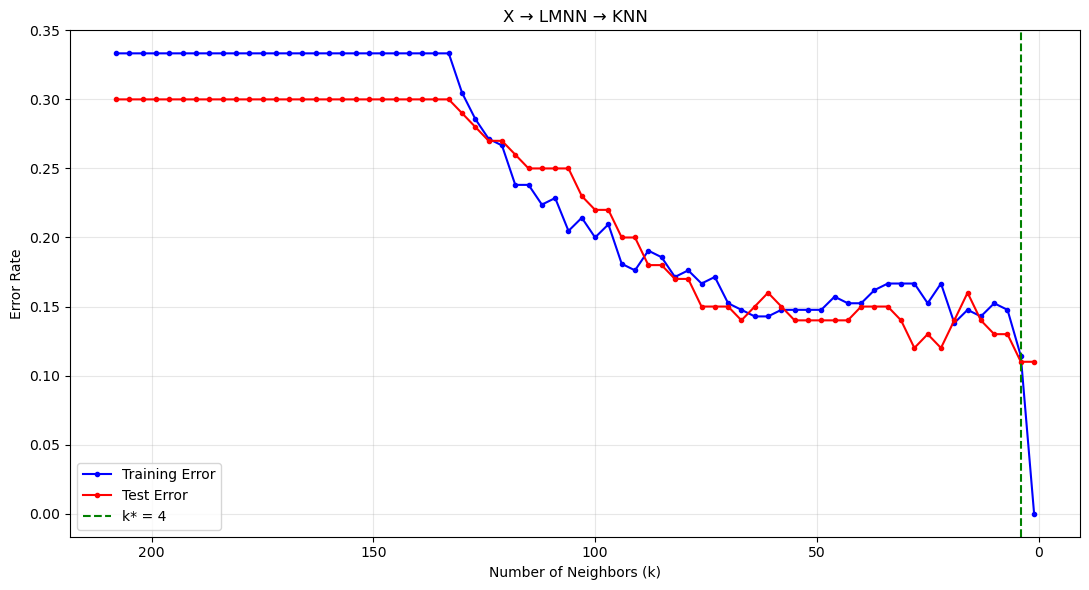


Pipeline: X -> LMNN -> KNN
Features: ['PT', 'LL', 'SS', 'PR', 'GS']
LMNN n_neighbors: 3
Best KNN k values: [4, 1]
Selected KNN k*: 4

Training error: 0.11428571428571428
Test error: 0.11
Test accuracy: 0.89

Confusion Matrix:
[[24  6]
 [ 5 65]]

TN: 24
FP: 6
FN: 5
TP: 65

True Positive Rate: 0.9285714285714286
True Negative Rate: 0.8
Precision: 0.9154929577464789
F1-score: 0.921985815602837


In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tkinter import Tk, filedialog

from sklearn import set_config
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    f1_score
)

from metric_learn import LMNN

# Avoid the threadpoolctl/OpenBLAS compatibility problem
try:
    set_config(enable_cython_pairwise_dist=False)
except TypeError:
    pass

# =========================================================
# 1. Select and load the dataset
# =========================================================
root = Tk()
root.withdraw()

file_path = filedialog.askopenfilename(
    title="Select column_2C.dat",
    filetypes=[
        ("Data files", "*.dat"),
        ("Text files", "*.txt"),
        ("All files", "*.*")
    ]
)

root.destroy()

if not file_path:
    raise ValueError("No dataset file was selected.")

column_names = [
    "PI",
    "PT",
    "LL",
    "SS",
    "PR",
    "GS",
    "Class"
]

df = pd.read_csv(
    file_path,
    sep=r"\s+",
    header=None,
    names=column_names
)

# Convert labels: NO = 0 and AB = 1
df["Class"] = df["Class"].map({
    "NO": 0,
    "AB": 1
})

if df["Class"].isna().any():
    raise ValueError(
        "The selected file is invalid. Select column_2C.dat."
    )

print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df["Class"].value_counts().sort_index())

# =========================================================
# 2. Create training and test sets
# =========================================================
class_0 = df[df["Class"] == 0]
class_1 = df[df["Class"] == 1]

# First 70 observations of Class 0
# First 140 observations of Class 1
train_df = pd.concat(
    [
        class_0.iloc[:70],
        class_1.iloc[:140]
    ],
    ignore_index=True
)

# Remaining observations
test_df = pd.concat(
    [
        class_0.iloc[70:],
        class_1.iloc[140:]
    ],
    ignore_index=True
)

print("\nTraining set shape:", train_df.shape)
print("Test set shape:", test_df.shape)

print("\nTraining class distribution:")
print(train_df["Class"].value_counts().sort_index())

print("\nTest class distribution:")
print(test_df["Class"].value_counts().sort_index())

# =========================================================
# 3. Remove PI
# PI is approximately equal to PT + SS
# =========================================================
selected_features = [
    "PT",
    "LL",
    "SS",
    "PR",
    "GS"
]

X_train = np.asarray(
    train_df[selected_features],
    dtype=np.float64,
    order="C"
)

X_test = np.asarray(
    test_df[selected_features],
    dtype=np.float64,
    order="C"
)

y_train = np.asarray(
    train_df["Class"],
    dtype=int
).ravel()

y_test = np.asarray(
    test_df["Class"],
    dtype=int
).ravel()

print("\nPipeline: X -> LMNN -> KNN")
print("Removed feature: PI")
print("Selected features:", selected_features)

# Check for missing values
if np.isnan(X_train).any():
    raise ValueError("X_train contains missing values.")

if np.isnan(X_test).any():
    raise ValueError("X_test contains missing values.")

# =========================================================
# 4. Fit and apply LMNN
# No StandardScaler is used
# =========================================================
lmnn = LMNN(
    n_neighbors=3,
    init="identity",
    n_components=None,
    max_iter=1000,
    learn_rate=1e-6,
    regularization=0.5,
    convergence_tol=1e-3,
    random_state=42,
    verbose=False
)

# Fit LMNN only on training data
lmnn.fit(X_train, y_train)

# Transform training and test data
X_train_lmnn = lmnn.transform(X_train)
X_test_lmnn = lmnn.transform(X_test)

X_train_lmnn = np.ascontiguousarray(
    X_train_lmnn,
    dtype=np.float64
)

X_test_lmnn = np.ascontiguousarray(
    X_test_lmnn,
    dtype=np.float64
)

print("\nLMNN iterations:", lmnn.n_iter_)
print("Input dimensions:", X_train.shape[1])
print("LMNN output dimensions:", X_train_lmnn.shape[1])

# =========================================================
# 5. Define all requested KNN k values
# 208, 205, ..., 7, 4, 1
# =========================================================
k_values = list(range(208, 0, -3))

k_values = [
    k
    for k in k_values
    if k <= len(X_train_lmnn)
]

train_errors = []
test_errors = []

# =========================================================
# 6. Evaluate KNN for every k
# =========================================================
for k in k_values:

    knn = KNeighborsClassifier(
        n_neighbors=k,
        metric="euclidean",
        weights="uniform",
        algorithm="kd_tree"
    )

    knn.fit(X_train_lmnn, y_train)

    train_predictions = knn.predict(
        X_train_lmnn
    )

    test_predictions = knn.predict(
        X_test_lmnn
    )

    train_error = np.mean(
        train_predictions != y_train
    )

    test_error = np.mean(
        test_predictions != y_test
    )

    train_errors.append(train_error)
    test_errors.append(test_error)

# =========================================================
# 7. Find the optimal k
# =========================================================
minimum_test_error = min(test_errors)

best_k_values = [
    k
    for k, error in zip(k_values, test_errors)
    if np.isclose(error, minimum_test_error)
]

# Select the largest k in case of a tie
k_star = max(best_k_values)

# =========================================================
# 8. Plot training and test errors
# =========================================================
plt.figure(figsize=(11, 6))

plt.plot(
    k_values,
    train_errors,
    color="blue",
    marker="o",
    markersize=3,
    label="Training Error"
)

plt.plot(
    k_values,
    test_errors,
    color="red",
    marker="o",
    markersize=3,
    label="Test Error"
)

plt.axvline(
    k_star,
    color="green",
    linestyle="--",
    label=f"k* = {k_star}"
)

plt.gca().invert_xaxis()

plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Error Rate")
plt.title("X → LMNN → KNN")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# =========================================================
# 9. Train the final KNN model
# =========================================================
final_knn = KNeighborsClassifier(
    n_neighbors=k_star,
    metric="euclidean",
    weights="uniform",
    algorithm="kd_tree"
)

final_knn.fit(
    X_train_lmnn,
    y_train
)

final_train_predictions = final_knn.predict(
    X_train_lmnn
)

final_test_predictions = final_knn.predict(
    X_test_lmnn
)

# =========================================================
# 10. Calculate final errors
# =========================================================
training_error = np.mean(
    final_train_predictions != y_train
)

test_error = np.mean(
    final_test_predictions != y_test
)

test_accuracy = np.mean(
    final_test_predictions == y_test
)

# =========================================================
# 11. Calculate confusion matrix
# =========================================================
cm = confusion_matrix(
    y_test,
    final_test_predictions,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

# =========================================================
# 12. Calculate evaluation metrics
# =========================================================
true_positive_rate = (
    tp / (tp + fn)
    if (tp + fn) > 0
    else 0
)

true_negative_rate = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else 0
)

precision = precision_score(
    y_test,
    final_test_predictions,
    pos_label=1,
    zero_division=0
)

f1 = f1_score(
    y_test,
    final_test_predictions,
    pos_label=1,
    zero_division=0
)

# =========================================================
# 13. Display final results
# =========================================================
print("\n" + "=" * 50)
print("Pipeline: X -> LMNN -> KNN")
print("Features:", selected_features)
print("LMNN n_neighbors:", lmnn.n_neighbors)
print("Best KNN k values:", best_k_values)
print("Selected KNN k*:", k_star)

print("\nTraining error:", training_error)
print("Test error:", test_error)
print("Test accuracy:", test_accuracy)

print("\nConfusion Matrix:")
print(cm)

print("\nTN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

print("\nTrue Positive Rate:", true_positive_rate)
print("True Negative Rate:", true_negative_rate)
print("Precision:", precision)
print("F1-score:", f1)

The LMNN–KNN pipeline achieved its best performance at \(k=4\), with 89% test accuracy and an 11% test error. Although the model showed strong TPR (92.86%) and F1-score (92.20%), it performed worse than the feature-engineered KNN model without scaling, which achieved 92% test accuracy. Therefore, LMNN did not improve classification performance in this case.

### X→StandardScaler→LMNN→KNN (extra)
In this pipeline, standard scaling was applied before LMNN. The scaler was fitted to the training data and then used to transform both the training and test sets. LMNN subsequently learned a new distance-based representation from the standardized training data, and KNN performed the final classification in the transformed feature space.

In [15]:
%pip install metric-learn

Note: you may need to restart the kernel to use updated packages.


Dataset shape: (310, 7)

Class distribution:
Class
0    100
1    210
Name: count, dtype: int64

Training set shape: (210, 7)
Test set shape: (100, 7)

Training class distribution:
Class
0     70
1    140
Name: count, dtype: int64

Test class distribution:
Class
0    30
1    70
Name: count, dtype: int64

Pipeline: X -> StandardScaler -> LMNN -> KNN
Removed feature: PI
Selected features: ['PT', 'LL', 'SS', 'PR', 'GS']

StandardScaler was fitted on training data.
LMNN iterations: 428
Input dimensions: 5
LMNN output dimensions: 5


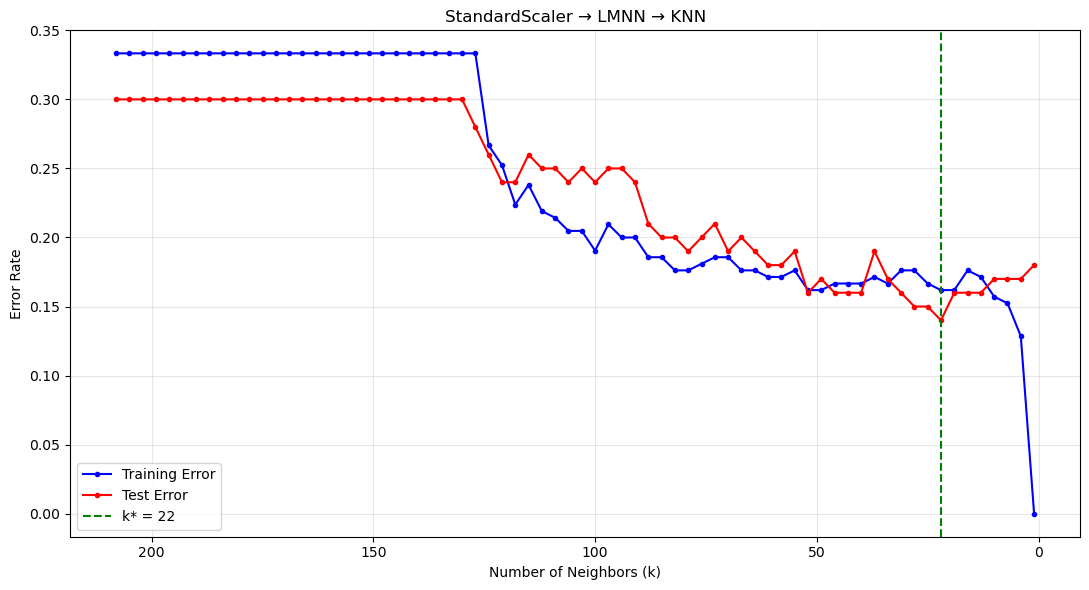


Pipeline: X -> StandardScaler -> LMNN -> KNN
Features: ['PT', 'LL', 'SS', 'PR', 'GS']
LMNN n_neighbors: 3
Best KNN k values: [22]
Selected KNN k*: 22

Training error: 0.1619047619047619
Test error: 0.14
Test accuracy: 0.86

Confusion Matrix:
[[19 11]
 [ 3 67]]

TN: 19
FP: 11
FN: 3
TP: 67

True Positive Rate: 0.9571428571428572
True Negative Rate: 0.6333333333333333
Precision: 0.8589743589743589
F1-score: 0.9054054054054054


In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tkinter import Tk, filedialog

from sklearn import set_config
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    f1_score
)

from metric_learn import LMNN

# Avoid the threadpoolctl/OpenBLAS compatibility problem
try:
    set_config(enable_cython_pairwise_dist=False)
except TypeError:
    pass

# =========================================================
# 1. Select and load column_2C.dat
# =========================================================
root = Tk()
root.withdraw()

file_path = filedialog.askopenfilename(
    title="Select column_2C.dat",
    filetypes=[
        ("Data files", "*.dat"),
        ("Text files", "*.txt"),
        ("All files", "*.*")
    ]
)

root.destroy()

if not file_path:
    raise ValueError("No dataset file was selected.")

column_names = [
    "PI",
    "PT",
    "LL",
    "SS",
    "PR",
    "GS",
    "Class"
]

df = pd.read_csv(
    file_path,
    sep=r"\s+",
    header=None,
    names=column_names
)

# Convert labels to binary values
df["Class"] = df["Class"].map({
    "NO": 0,
    "AB": 1
})

if df["Class"].isna().any():
    raise ValueError(
        "Select the binary dataset: column_2C.dat"
    )

print("Dataset shape:", df.shape)

print("\nClass distribution:")
print(df["Class"].value_counts().sort_index())

# =========================================================
# 2. Create training and test sets
# =========================================================
class_0 = df[df["Class"] == 0]
class_1 = df[df["Class"] == 1]

train_df = pd.concat(
    [
        class_0.iloc[:70],
        class_1.iloc[:140]
    ],
    ignore_index=True
)

test_df = pd.concat(
    [
        class_0.iloc[70:],
        class_1.iloc[140:]
    ],
    ignore_index=True
)

print("\nTraining set shape:", train_df.shape)
print("Test set shape:", test_df.shape)

print("\nTraining class distribution:")
print(train_df["Class"].value_counts().sort_index())

print("\nTest class distribution:")
print(test_df["Class"].value_counts().sort_index())

# =========================================================
# 3. Select features
# PI is removed because PI is approximately PT + SS
# =========================================================
selected_features = [
    "PT",
    "LL",
    "SS",
    "PR",
    "GS"
]

X_train = np.asarray(
    train_df[selected_features],
    dtype=np.float64,
    order="C"
)

X_test = np.asarray(
    test_df[selected_features],
    dtype=np.float64,
    order="C"
)

y_train = np.asarray(
    train_df["Class"],
    dtype=int
).ravel()

y_test = np.asarray(
    test_df["Class"],
    dtype=int
).ravel()

print("\nPipeline: X -> StandardScaler -> LMNN -> KNN")
print("Removed feature: PI")
print("Selected features:", selected_features)

# Check for missing values
if np.isnan(X_train).any():
    raise ValueError("X_train contains missing values.")

if np.isnan(X_test).any():
    raise ValueError("X_test contains missing values.")

# =========================================================
# 4. Apply StandardScaler
# Fit only on training data
# =========================================================
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train
)

X_test_scaled = scaler.transform(
    X_test
)

X_train_scaled = np.ascontiguousarray(
    X_train_scaled,
    dtype=np.float64
)

X_test_scaled = np.ascontiguousarray(
    X_test_scaled,
    dtype=np.float64
)

print("\nStandardScaler was fitted on training data.")

# =========================================================
# 5. Fit and apply LMNN
# =========================================================
lmnn = LMNN(
    n_neighbors=3,
    init="identity",
    n_components=None,
    max_iter=1000,
    learn_rate=1e-6,
    regularization=0.5,
    convergence_tol=1e-3,
    random_state=42,
    verbose=False
)

# Fit LMNN only on scaled training data
lmnn.fit(
    X_train_scaled,
    y_train
)

# Transform scaled training and test data
X_train_lmnn = lmnn.transform(
    X_train_scaled
)

X_test_lmnn = lmnn.transform(
    X_test_scaled
)

X_train_lmnn = np.ascontiguousarray(
    X_train_lmnn,
    dtype=np.float64
)

X_test_lmnn = np.ascontiguousarray(
    X_test_lmnn,
    dtype=np.float64
)

print("LMNN iterations:", lmnn.n_iter_)
print("Input dimensions:", X_train.shape[1])
print("LMNN output dimensions:", X_train_lmnn.shape[1])

# =========================================================
# 6. Define all requested KNN k values
# 208, 205, ..., 7, 4, 1
# =========================================================
k_values = list(range(208, 0, -3))

k_values = [
    k
    for k in k_values
    if k <= len(X_train_lmnn)
]

train_errors = []
test_errors = []

# =========================================================
# 7. Evaluate KNN for every k
# =========================================================
for k in k_values:

    knn = KNeighborsClassifier(
        n_neighbors=k,
        metric="euclidean",
        weights="uniform",
        algorithm="kd_tree"
    )

    knn.fit(
        X_train_lmnn,
        y_train
    )

    train_predictions = knn.predict(
        X_train_lmnn
    )

    test_predictions = knn.predict(
        X_test_lmnn
    )

    train_error = np.mean(
        train_predictions != y_train
    )

    test_error = np.mean(
        test_predictions != y_test
    )

    train_errors.append(train_error)
    test_errors.append(test_error)

# =========================================================
# 8. Find the optimal k
# =========================================================
minimum_test_error = min(test_errors)

best_k_values = [
    k
    for k, error in zip(k_values, test_errors)
    if np.isclose(error, minimum_test_error)
]

# Select the largest k in case of a tie
k_star = max(best_k_values)

# =========================================================
# 9. Plot training and test errors
# =========================================================
plt.figure(figsize=(11, 6))

plt.plot(
    k_values,
    train_errors,
    color="blue",
    marker="o",
    markersize=3,
    label="Training Error"
)

plt.plot(
    k_values,
    test_errors,
    color="red",
    marker="o",
    markersize=3,
    label="Test Error"
)

plt.axvline(
    k_star,
    color="green",
    linestyle="--",
    label=f"k* = {k_star}"
)

plt.gca().invert_xaxis()

plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Error Rate")
plt.title("StandardScaler → LMNN → KNN")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# =========================================================
# 10. Train the final KNN model
# =========================================================
final_knn = KNeighborsClassifier(
    n_neighbors=k_star,
    metric="euclidean",
    weights="uniform",
    algorithm="kd_tree"
)

final_knn.fit(
    X_train_lmnn,
    y_train
)

final_train_predictions = final_knn.predict(
    X_train_lmnn
)

final_test_predictions = final_knn.predict(
    X_test_lmnn
)

# =========================================================
# 11. Calculate final error rates
# =========================================================
training_error = np.mean(
    final_train_predictions != y_train
)

test_error = np.mean(
    final_test_predictions != y_test
)

test_accuracy = np.mean(
    final_test_predictions == y_test
)

# =========================================================
# 12. Calculate confusion matrix
# =========================================================
cm = confusion_matrix(
    y_test,
    final_test_predictions,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

# =========================================================
# 13. Calculate evaluation metrics
# =========================================================
true_positive_rate = (
    tp / (tp + fn)
    if (tp + fn) > 0
    else 0
)

true_negative_rate = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else 0
)

precision = precision_score(
    y_test,
    final_test_predictions,
    pos_label=1,
    zero_division=0
)

f1 = f1_score(
    y_test,
    final_test_predictions,
    pos_label=1,
    zero_division=0
)

# =========================================================
# 14. Display final results
# =========================================================
print("\n" + "=" * 55)
print("Pipeline: X -> StandardScaler -> LMNN -> KNN")
print("Features:", selected_features)
print("LMNN n_neighbors:", lmnn.n_neighbors)
print("Best KNN k values:", best_k_values)
print("Selected KNN k*:", k_star)

print("\nTraining error:", training_error)
print("Test error:", test_error)
print("Test accuracy:", test_accuracy)

print("\nConfusion Matrix:")
print(cm)

print("\nTN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

print("\nTrue Positive Rate:", true_positive_rate)
print("True Negative Rate:", true_negative_rate)
print("Precision:", precision)
print("F1-score:", f1)

In [ ]:
The StandardScaler–LMNN–KNN pipeline achieved its best performance at \(k=22\), with 86% test accuracy and a 14% test error.
Although it identified abnormal cases well (TPR = 95.71%), its lower TNR of 63.33% indicates weaker identification of normal cases. Overall, applying scaling before LMNN reduced performance compared with the LMNN–KNN pipeline without scaling.

# Part (c) , (iii)
#### Train subset⟶Fit several k⟶Evaluate on test set⟶Select best k (Construct a learning curve using)
In this stage, a learning curve was constructed to examine how the size of the training set affects KNN performance and computational requirements. Training subsets of size \(N \in \{10,20,30,\ldots,210\}\) were created. For each \(N\), the subset contained the first \(\lfloor N/3 \rfloor\) observations from Class 0 and the first \(N-\lfloor N/3 \rfloor\) observations from Class 1. Several candidate values of \(k\), starting from 1 and increasing by 5, were then evaluated using the fixed test set. For each training size, the \(k\) producing the lowest test error was selected. Finally, the best test error was plotted against \(N\) to construct the learning curve.

Learning Curve Results:


,Training Size (N),All Best k Values,Selected k,Best Test Error,Best Test Accuracy
0,10,[1],1,0.25,0.75
1,20,[6],6,0.20,0.80
2,30,[1],1,0.22,0.78
3,40,[11],11,0.25,0.75
4,50,"[26, 31, 36, 41, 46]",46,0.30,0.70
5,60,[21],21,0.29,0.71
6,70,"[26, 31]",31,0.29,0.71
7,80,"[31, 36]",36,0.29,0.71
8,90,"[41, 46]",46,0.29,0.71
9,100,[6],6,0.25,0.75


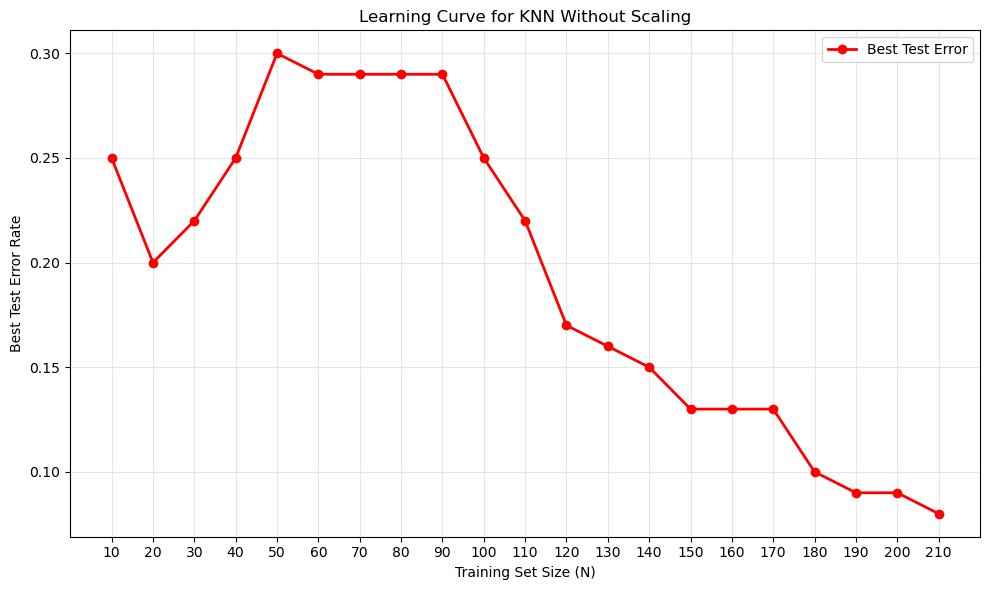

N =  10 | Best k values = [1] | Selected k =   1 | Best test error = 0.2500
N =  20 | Best k values = [6] | Selected k =   6 | Best test error = 0.2000
N =  30 | Best k values = [1] | Selected k =   1 | Best test error = 0.2200
N =  40 | Best k values = [11] | Selected k =  11 | Best test error = 0.2500
N =  50 | Best k values = [26, 31, 36, 41, 46] | Selected k =  46 | Best test error = 0.3000
N =  60 | Best k values = [21] | Selected k =  21 | Best test error = 0.2900
N =  70 | Best k values = [26, 31] | Selected k =  31 | Best test error = 0.2900
N =  80 | Best k values = [31, 36] | Selected k =  36 | Best test error = 0.2900
N =  90 | Best k values = [41, 46] | Selected k =  46 | Best test error = 0.2900
N = 100 | Best k values = [6] | Selected k =   6 | Best test error = 0.2500
N = 110 | Best k values = [6] | Selected k =   6 | Best test error = 0.2200
N = 120 | Best k values = [16] | Selected k =  16 | Best test error = 0.1700
N = 130 | Best k values = [16] | Selected k =  16 | B

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn import set_config
from sklearn.neighbors import KNeighborsClassifier

# Avoid the threadpoolctl/OpenBLAS compatibility problem
try:
    set_config(enable_cython_pairwise_dist=False)
except TypeError:
    pass

# ---------------------------------------------------------
# 1. Use all six input features without scaling
# ---------------------------------------------------------
features = [
    "PI",
    "PT",
    "LL",
    "SS",
    "PR",
    "GS"
]

# Fixed test set created in Part 1(b)iii
X_test_fixed = np.asarray(
    test_df[features],
    dtype=np.float64,
    order="C"
)

y_test_fixed = np.asarray(
    test_df["Class"],
    dtype=int
).ravel()

# Separate the original training set by class
train_class_0 = train_df[
    train_df["Class"] == 0
].reset_index(drop=True)

train_class_1 = train_df[
    train_df["Class"] == 1
].reset_index(drop=True)

# ---------------------------------------------------------
# 2. Define training-set sizes
# ---------------------------------------------------------
N_values = list(range(10, 211, 10))

best_test_errors = []
selected_k_values = []
all_best_k_values = []

# ---------------------------------------------------------
# 3. Repeat the procedure for every N
# ---------------------------------------------------------
for N in N_values:

    # Number of observations from each class
    number_class_0 = N // 3
    number_class_1 = N - number_class_0

    # Select the first observations from each class
    subset_class_0 = train_class_0.iloc[
        :number_class_0
    ]

    subset_class_1 = train_class_1.iloc[
        :number_class_1
    ]

    # Combine both classes
    train_subset = pd.concat(
        [
            subset_class_0,
            subset_class_1
        ],
        ignore_index=True
    )

    # Create input features and labels
    X_train_subset = np.asarray(
        train_subset[features],
        dtype=np.float64,
        order="C"
    )

    y_train_subset = np.asarray(
        train_subset["Class"],
        dtype=int
    ).ravel()

    # Candidate k values: 1, 6, 11, ...
    # All k values must be smaller than N
    k_candidates = list(
        range(1, N, 5)
    )

    test_errors_for_N = []

    # -----------------------------------------------------
    # 4. Fit and evaluate every candidate k
    # -----------------------------------------------------
    for k in k_candidates:

        knn = KNeighborsClassifier(
            n_neighbors=k,
            metric="euclidean",
            weights="uniform",
            algorithm="kd_tree"
        )

        # Fit KNN on the current training subset
        knn.fit(
            X_train_subset,
            y_train_subset
        )

        # Evaluate on the fixed test set
        test_predictions = knn.predict(
            X_test_fixed
        )

        test_error = np.mean(
            test_predictions != y_test_fixed
        )

        test_errors_for_N.append(
            test_error
        )

    # -----------------------------------------------------
    # 5. Select the best k for the current N
    # -----------------------------------------------------
    minimum_error = min(
        test_errors_for_N
    )

    best_k_for_N = [
        k
        for k, error in zip(
            k_candidates,
            test_errors_for_N
        )
        if np.isclose(error, minimum_error)
    ]

    # Select the largest k in case of a tie
    selected_k = max(best_k_for_N)

    best_test_errors.append(
        minimum_error
    )

    selected_k_values.append(
        selected_k
    )

    all_best_k_values.append(
        best_k_for_N
    )

# ---------------------------------------------------------
# 6. Create the results table
# ---------------------------------------------------------
learning_curve_results = pd.DataFrame({
    "Training Size (N)": N_values,
    "All Best k Values": all_best_k_values,
    "Selected k": selected_k_values,
    "Best Test Error": best_test_errors,
    "Best Test Accuracy": [
        1 - error
        for error in best_test_errors
    ]
})

print("Learning Curve Results:")
display(
    learning_curve_results.round(4)
)

# ---------------------------------------------------------
# 7. Plot the learning curve
# ---------------------------------------------------------
plt.figure(figsize=(10, 6))

plt.plot(
    N_values,
    best_test_errors,
    color="red",
    marker="o",
    linewidth=2,
    label="Best Test Error"
)

plt.xlabel("Training Set Size (N)")
plt.ylabel("Best Test Error Rate")
plt.title(
    "Learning Curve for KNN Without Scaling"
)

plt.xticks(N_values)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 8. Print detailed results
# ---------------------------------------------------------
for N, best_ks, selected_k, error in zip(
    N_values,
    all_best_k_values,
    selected_k_values,
    best_test_errors
):
    print(
        f"N = {N:3d} | "
        f"Best k values = {best_ks} | "
        f"Selected k = {selected_k:3d} | "
        f"Best test error = {error:.4f}"
    )

The learning curve generally shows that KNN performance improves as the training-set size increases. Although the test error does not decrease monotonically, it shows a clear downward trend after \(N=110\). The best result was obtained using all 210 training observations with \(k=6\), resulting in a test error of 8% and a test accuracy of 92%. The fluctuations observed for smaller training sets may be attributed to the limited amount of training data and the deterministic selection of the first observations from each class

# Part(d) : Replace the Euclidean metric with the following metrics(i, ii)

In this stage, alternative methods for measuring the distance between observations were evaluated to determine whether they could improve KNN performance. The examined metrics included Manhattan distance, Minkowski distance with different values of \(p\), Chebyshev distance, and Mahalanobis distance. For each metric, the candidate values of \(k\) specified in the assignment were tested, and the value producing the lowest test error was selected.

Features: ['PI', 'PT', 'LL', 'SS', 'PR', 'GS']
Number of training observations: 210
Candidate k values: [1, 6, 11, 16, 21, 26, 31, 36, 41, 46, 51, 56, 61, 66, 71, 76, 81, 86, 91, 96, 101, 106, 111, 116, 121, 126, 131, 136, 141, 146, 151, 156, 161, 166, 171, 176, 181, 186, 191, 196]

Manhattan Distance:
Best k values: [6, 11, 26]
Selected k*: 26
Minimum test error: 0.11

Minkowski p Results:


,log10(p),p,k,Test Error,Test Accuracy
0,0.1,1.2589,26,0.10,0.90
1,0.2,1.5849,26,0.10,0.90
2,0.3,1.9953,26,0.11,0.89
3,0.4,2.5119,26,0.10,0.90
4,0.5,3.1623,26,0.11,0.89
5,0.6,3.9811,26,0.10,0.90
6,0.7,5.0119,26,0.11,0.89
7,0.8,6.3096,26,0.11,0.89
8,0.9,7.9433,26,0.11,0.89
9,1.0,10.0000,26,0.11,0.89


Best log10(p): 0.1
Best p: 1.2589
Minimum test error: 0.1

Chebyshev Distance:
Best k values: [16]
Selected k*: 16
Minimum test error: 0.08

Covariance Matrix Information:
Matrix rank: 6
Number of features: 6
Condition number: 201192357.7915328
The covariance matrix has full rank. The pseudoinverse is still used for stability.

Mahalanobis Distance:
Best k values: [1, 6]
Selected k*: 6
Minimum test error: 0.17

Final Distance Comparison:


,Distance,Parameter,Selected k,Test Error,Test Accuracy
0,Manhattan,p = 1,26,0.11,0.89
1,Minkowski,"log10(p) = 0.1, p = 1.2589",26,0.10,0.90
2,Chebyshev,p → infinity,16,0.08,0.92
3,Mahalanobis,Covariance pseudoinverse,6,0.17,0.83


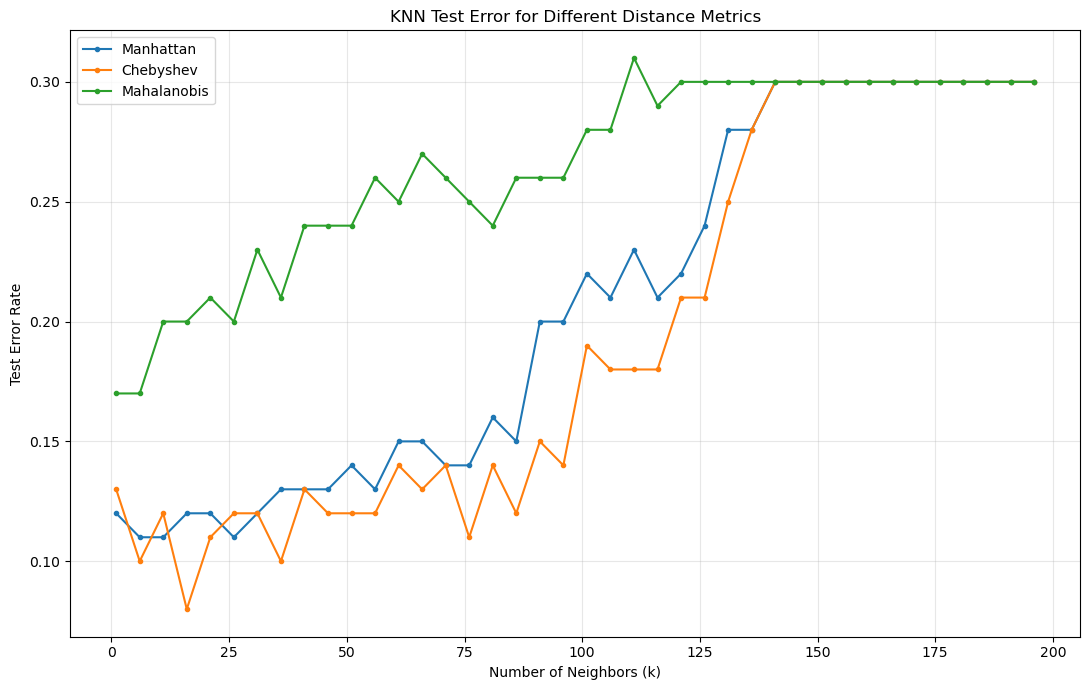

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn import set_config
from sklearn.neighbors import KNeighborsClassifier

# Avoid the threadpoolctl/OpenBLAS compatibility problem
try:
    set_config(enable_cython_pairwise_dist=False)
except TypeError:
    pass

# =========================================================
# 1. Prepare the full training and test sets
# =========================================================
features = [
    "PI",
    "PT",
    "LL",
    "SS",
    "PR",
    "GS"
]

X_train_array = np.asarray(
    train_df[features],
    dtype=np.float64,
    order="C"
)

X_test_array = np.asarray(
    test_df[features],
    dtype=np.float64,
    order="C"
)

y_train_array = np.asarray(
    train_df["Class"],
    dtype=int
).ravel()

y_test_array = np.asarray(
    test_df["Class"],
    dtype=int
).ravel()

# Check for missing values
if np.isnan(X_train_array).any():
    raise ValueError(
        "Training data contain missing values."
    )

if np.isnan(X_test_array).any():
    raise ValueError(
        "Test data contain missing values."
    )

# Candidate k values: 1, 6, 11, ..., 196
k_values = list(range(1, 197, 5))

print("Features:", features)
print("Number of training observations:", len(X_train_array))
print("Candidate k values:", k_values)

# =========================================================
# 2. Function for evaluating a distance metric
# =========================================================
def evaluate_distance(
    metric,
    metric_name,
    metric_params=None,
    p=2
):
    test_errors = []

    for k in k_values:

        knn = KNeighborsClassifier(
            n_neighbors=k,
            metric=metric,
            metric_params=metric_params,
            p=p,
            weights="uniform",
            algorithm="ball_tree"
        )

        knn.fit(
            X_train_array,
            y_train_array
        )

        predictions = knn.predict(
            X_test_array
        )

        test_error = np.mean(
            predictions != y_test_array
        )

        test_errors.append(test_error)

    minimum_error = min(test_errors)

    best_k_values = [
        k
        for k, error in zip(
            k_values,
            test_errors
        )
        if np.isclose(error, minimum_error)
    ]

    # Select the largest k in case of a tie
    selected_k = max(best_k_values)

    return {
        "Metric": metric_name,
        "Best k Values": best_k_values,
        "Selected k": selected_k,
        "Test Error": minimum_error,
        "Test Accuracy": 1 - minimum_error,
        "All Test Errors": test_errors
    }

# =========================================================
# 3. Manhattan distance
# Minkowski distance with p = 1
# =========================================================
manhattan_result = evaluate_distance(
    metric="minkowski",
    metric_name="Manhattan",
    p=1
)

manhattan_k_star = manhattan_result[
    "Selected k"
]

print("\nManhattan Distance:")
print(
    "Best k values:",
    manhattan_result["Best k Values"]
)
print(
    "Selected k*:",
    manhattan_k_star
)
print(
    "Minimum test error:",
    manhattan_result["Test Error"]
)

# =========================================================
# 4. Minkowski distance
# Use Manhattan k* and test different p values
# =========================================================
log10_p_values = np.arange(
    0.1,
    1.01,
    0.1
)

minkowski_p_results = []

for log10_p in log10_p_values:

    p_value = 10 ** log10_p

    knn = KNeighborsClassifier(
        n_neighbors=manhattan_k_star,
        metric="minkowski",
        p=p_value,
        weights="uniform",
        algorithm="ball_tree"
    )

    knn.fit(
        X_train_array,
        y_train_array
    )

    predictions = knn.predict(
        X_test_array
    )

    test_error = np.mean(
        predictions != y_test_array
    )

    minkowski_p_results.append({
        "log10(p)": log10_p,
        "p": p_value,
        "k": manhattan_k_star,
        "Test Error": test_error,
        "Test Accuracy": 1 - test_error
    })

minkowski_p_table = pd.DataFrame(
    minkowski_p_results
)

minimum_minkowski_error = (
    minkowski_p_table["Test Error"].min()
)

best_minkowski_rows = minkowski_p_table[
    np.isclose(
        minkowski_p_table["Test Error"],
        minimum_minkowski_error
    )
]

# Select the smallest log10(p) in case of a tie
best_minkowski_row = (
    best_minkowski_rows
    .sort_values("log10(p)")
    .iloc[0]
)

best_log10_p = best_minkowski_row[
    "log10(p)"
]

best_p = best_minkowski_row["p"]

print("\nMinkowski p Results:")
display(
    minkowski_p_table.round(4)
)

print(
    "Best log10(p):",
    round(best_log10_p, 4)
)
print(
    "Best p:",
    round(best_p, 4)
)
print(
    "Minimum test error:",
    minimum_minkowski_error
)

# =========================================================
# 5. Chebyshev distance
# Equivalent to p approaching infinity
# =========================================================
chebyshev_result = evaluate_distance(
    metric="chebyshev",
    metric_name="Chebyshev"
)

print("\nChebyshev Distance:")
print(
    "Best k values:",
    chebyshev_result["Best k Values"]
)
print(
    "Selected k*:",
    chebyshev_result["Selected k"]
)
print(
    "Minimum test error:",
    chebyshev_result["Test Error"]
)

# =========================================================
# 6. Mahalanobis distance
# Use the pseudoinverse of the covariance matrix
# =========================================================
covariance_matrix = np.cov(
    X_train_array,
    rowvar=False
)

covariance_rank = np.linalg.matrix_rank(
    covariance_matrix
)

condition_number = np.linalg.cond(
    covariance_matrix
)

# Pseudoinverse works for singular matrices
inverse_covariance = np.linalg.pinv(
    covariance_matrix
)

# Ensure numerical symmetry
inverse_covariance = (
    inverse_covariance
    + inverse_covariance.T
) / 2

print("\nCovariance Matrix Information:")
print("Matrix rank:", covariance_rank)
print(
    "Number of features:",
    X_train_array.shape[1]
)
print("Condition number:", condition_number)

if covariance_rank < X_train_array.shape[1]:
    print(
        "The covariance matrix is singular. "
        "The pseudoinverse is used."
    )
else:
    print(
        "The covariance matrix has full rank. "
        "The pseudoinverse is still used for stability."
    )

mahalanobis_result = evaluate_distance(
    metric="mahalanobis",
    metric_name="Mahalanobis",
    metric_params={
        "VI": inverse_covariance
    }
)

print("\nMahalanobis Distance:")
print(
    "Best k values:",
    mahalanobis_result["Best k Values"]
)
print(
    "Selected k*:",
    mahalanobis_result["Selected k"]
)
print(
    "Minimum test error:",
    mahalanobis_result["Test Error"]
)

# =========================================================
# 7. Create the final summary table
# =========================================================
summary_table = pd.DataFrame([
    {
        "Distance": "Manhattan",
        "Parameter": "p = 1",
        "Selected k": manhattan_result[
            "Selected k"
        ],
        "Test Error": manhattan_result[
            "Test Error"
        ],
        "Test Accuracy": manhattan_result[
            "Test Accuracy"
        ]
    },
    {
        "Distance": "Minkowski",
        "Parameter": (
            f"log10(p) = {best_log10_p:.1f}, "
            f"p = {best_p:.4f}"
        ),
        "Selected k": manhattan_k_star,
        "Test Error": minimum_minkowski_error,
        "Test Accuracy": (
            1 - minimum_minkowski_error
        )
    },
    {
        "Distance": "Chebyshev",
        "Parameter": "p → infinity",
        "Selected k": chebyshev_result[
            "Selected k"
        ],
        "Test Error": chebyshev_result[
            "Test Error"
        ],
        "Test Accuracy": chebyshev_result[
            "Test Accuracy"
        ]
    },
    {
        "Distance": "Mahalanobis",
        "Parameter": "Covariance pseudoinverse",
        "Selected k": mahalanobis_result[
            "Selected k"
        ],
        "Test Error": mahalanobis_result[
            "Test Error"
        ],
        "Test Accuracy": mahalanobis_result[
            "Test Accuracy"
        ]
    }
])

print("\nFinal Distance Comparison:")
display(
    summary_table.round(4)
)

# =========================================================
# 8. Plot test errors for k-dependent metrics
# =========================================================
plt.figure(figsize=(11, 7))

plt.plot(
    k_values,
    manhattan_result["All Test Errors"],
    marker="o",
    markersize=3,
    label="Manhattan"
)

plt.plot(
    k_values,
    chebyshev_result["All Test Errors"],
    marker="o",
    markersize=3,
    label="Chebyshev"
)

plt.plot(
    k_values,
    mahalanobis_result["All Test Errors"],
    marker="o",
    markersize=3,
    label="Mahalanobis"
)

plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Test Error Rate")
plt.title(
    "KNN Test Error for Different Distance Metrics"
)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

From this stage onward, all calculations were performed using standard KNN on the original unscaled data; neither feature scaling nor LMNN was applied. 
Among the alternative distance metrics, Chebyshev distance achieved the best performance at \(k=16\), with a test error of 8% and a test accuracy of 92%. Minkowski distance ranked second with a minimum test error of 10%, while Manhattan distance achieved 11%. Mahalanobis distance produced the highest error of 17%. At very large values of \(k\), the test error approached 30% because predictions became dominated by the majority abnormal class. Overall, the original unscaled Euclidean KNN remained the best-performing model, achieving a test error of 6% at k=4

# Part(e) : Weighted KNN
In this stage, distance-weighted KNN was applied instead of standard majority voting. In this approach, closer neighbors receive greater voting influence than more distant neighbors. Weighted KNN was evaluated using Euclidean, Manhattan, and Chebyshev distance metrics to identify the combination that produced the lowest test error.

Weighted KNN Results:


,Distance,Best k Values,Selected k,Best Test Error,Best Test Accuracy
0,Euclidean,[6],6,0.10,0.90
1,Manhattan,[26],26,0.10,0.90
2,Chebyshev,"[16, 31, 36, 41, 61]",61,0.11,0.89


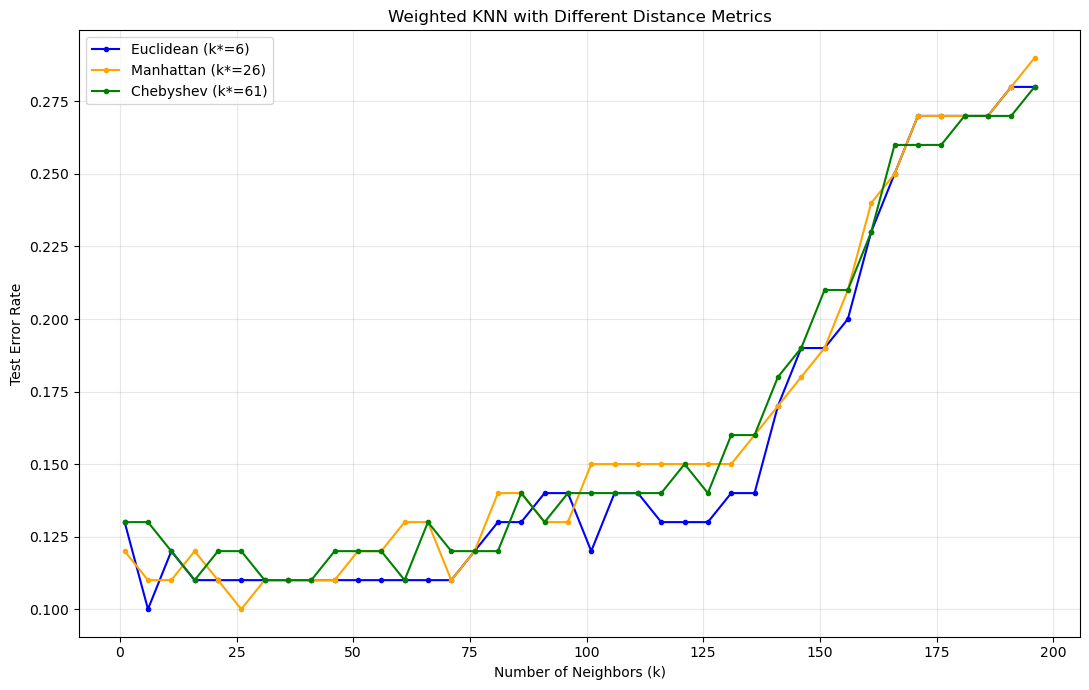


Distance: Euclidean
Best k values: [6]
Selected k*: 6
Best test error: 0.1
Best test accuracy: 0.9

Distance: Manhattan
Best k values: [26]
Selected k*: 26
Best test error: 0.1
Best test accuracy: 0.9

Distance: Chebyshev
Best k values: [16, 31, 36, 41, 61]
Selected k*: 61
Best test error: 0.11
Best test accuracy: 0.89

Best Weighted KNN Model(s):


,Distance,Best k Values,Selected k,Best Test Error,Best Test Accuracy
0,Euclidean,[6],6,0.1,0.9
1,Manhattan,[26],26,0.1,0.9


In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn import set_config
from sklearn.neighbors import KNeighborsClassifier

# Avoid the threadpoolctl/OpenBLAS compatibility problem
try:
    set_config(enable_cython_pairwise_dist=False)
except TypeError:
    pass

# =========================================================
# 1. Prepare training and test data
# =========================================================
features = [
    "PI",
    "PT",
    "LL",
    "SS",
    "PR",
    "GS"
]

X_train_array = np.asarray(
    train_df[features],
    dtype=np.float64,
    order="C"
)

X_test_array = np.asarray(
    test_df[features],
    dtype=np.float64,
    order="C"
)

y_train_array = np.asarray(
    train_df["Class"],
    dtype=int
).ravel()

y_test_array = np.asarray(
    test_df["Class"],
    dtype=int
).ravel()

# Check for missing values
if np.isnan(X_train_array).any():
    raise ValueError(
        "Training data contain missing values."
    )

if np.isnan(X_test_array).any():
    raise ValueError(
        "Test data contain missing values."
    )

# Candidate k values: 1, 6, 11, ..., 196
k_values = list(range(1, 197, 5))

# =========================================================
# 2. Define distance metrics
# =========================================================
distance_metrics = {
    "Euclidean": {
        "metric": "euclidean",
        "p": 2
    },
    "Manhattan": {
        "metric": "manhattan",
        "p": 1
    },
    "Chebyshev": {
        "metric": "chebyshev",
        "p": None
    }
}

all_results = {}
summary_rows = []

# =========================================================
# 3. Evaluate weighted KNN for each distance
# =========================================================
for distance_name, settings in distance_metrics.items():

    test_errors = []

    for k in k_values:

        knn = KNeighborsClassifier(
            n_neighbors=k,
            metric=settings["metric"],
            p=settings["p"],
            weights="distance",
            algorithm="ball_tree"
        )

        # Train the weighted KNN model
        knn.fit(
            X_train_array,
            y_train_array
        )

        # Predict the test labels
        test_predictions = knn.predict(
            X_test_array
        )

        # Calculate the test error
        test_error = np.mean(
            test_predictions != y_test_array
        )

        test_errors.append(test_error)

    # Find the minimum test error
    minimum_test_error = min(test_errors)

    # Find all k values with minimum error
    best_k_values = [
        k
        for k, error in zip(
            k_values,
            test_errors
        )
        if np.isclose(
            error,
            minimum_test_error
        )
    ]

    # Select the largest k in case of a tie
    selected_k = max(best_k_values)

    # Store complete results
    all_results[distance_name] = {
        "Test Errors": test_errors,
        "Best k Values": best_k_values,
        "Selected k": selected_k,
        "Test Error": minimum_test_error,
        "Test Accuracy": 1 - minimum_test_error
    }

    # Add a row to the summary table
    summary_rows.append({
        "Distance": distance_name,
        "Best k Values": best_k_values,
        "Selected k": selected_k,
        "Best Test Error": minimum_test_error,
        "Best Test Accuracy": (
            1 - minimum_test_error
        )
    })

# =========================================================
# 4. Create the final summary table
# =========================================================
weighted_knn_summary = pd.DataFrame(
    summary_rows
)

print("Weighted KNN Results:")
display(
    weighted_knn_summary.round(4)
)

# =========================================================
# 5. Plot test error curves
# =========================================================
plt.figure(figsize=(11, 7))

colors = {
    "Euclidean": "blue",
    "Manhattan": "orange",
    "Chebyshev": "green"
}

for distance_name, result in all_results.items():

    plt.plot(
        k_values,
        result["Test Errors"],
        marker="o",
        markersize=3,
        color=colors[distance_name],
        label=(
            f"{distance_name} "
            f"(k*={result['Selected k']})"
        )
    )

plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Test Error Rate")
plt.title(
    "Weighted KNN with Different Distance Metrics"
)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# =========================================================
# 6. Display detailed results
# =========================================================
for distance_name, result in all_results.items():

    print("\n" + "=" * 45)
    print("Distance:", distance_name)
    print(
        "Best k values:",
        result["Best k Values"]
    )
    print(
        "Selected k*:",
        result["Selected k"]
    )
    print(
        "Best test error:",
        result["Test Error"]
    )
    print(
        "Best test accuracy:",
        result["Test Accuracy"]
    )

# =========================================================
# 7. Identify the best weighted KNN model
# =========================================================
best_overall_error = weighted_knn_summary[
    "Best Test Error"
].min()

best_weighted_models = weighted_knn_summary[
    np.isclose(
        weighted_knn_summary[
            "Best Test Error"
        ],
        best_overall_error
    )
]

print("\nBest Weighted KNN Model(s):")
display(
    best_weighted_models.round(4)
)

The weighted Euclidean and Manhattan KNN models achieved the best and equal performance, with a test error of 10% and a test accuracy of 90%. Their optimal values were \(k=6\) and \(k=26\), respectively. Weighted Chebyshev KNN performed slightly worse, with an 11% test error. Overall, distance weighting did not improve upon the original unweighted Euclidean KNN, which achieved a lower test error of 6%.

# Part(f) :  Minimum Training Error

In [20]:
import numpy as np
import pandas as pd

from sklearn import set_config
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# Avoid the threadpoolctl/OpenBLAS compatibility problem
try:
    set_config(enable_cython_pairwise_dist=False)
except TypeError:
    pass

# =========================================================
# 1. Prepare the data
# =========================================================
features = [
    "PI",
    "PT",
    "LL",
    "SS",
    "PR",
    "GS"
]

X_train_original = np.asarray(
    train_df[features],
    dtype=np.float64,
    order="C"
)

X_test_original = np.asarray(
    test_df[features],
    dtype=np.float64,
    order="C"
)

y_train_array = np.asarray(
    train_df["Class"],
    dtype=int
).ravel()

y_test_array = np.asarray(
    test_df["Class"],
    dtype=int
).ravel()

# Standardized data
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train_original
)

X_test_scaled = scaler.transform(
    X_test_original
)

# k values for the Euclidean section
euclidean_k_values = list(
    range(208, 0, -3)
)

# k values for alternative distances
alternative_k_values = list(
    range(1, 197, 5)
)

# Store every evaluated model
all_trials = []

# Store the selected models
summary_rows = []

# =========================================================
# 2. General evaluation function
# =========================================================
def evaluate_model(
    model_name,
    X_train_data,
    X_test_data,
    k_candidates,
    metric,
    weights="uniform",
    p=2,
    metric_params=None,
    extra_parameter=""
):
    train_errors = []
    test_errors = []

    for k in k_candidates:

        model = KNeighborsClassifier(
            n_neighbors=k,
            metric=metric,
            p=p,
            metric_params=metric_params,
            weights=weights,
            algorithm="ball_tree"
        )

        model.fit(
            X_train_data,
            y_train_array
        )

        train_predictions = model.predict(
            X_train_data
        )

        test_predictions = model.predict(
            X_test_data
        )

        train_error = np.mean(
            train_predictions != y_train_array
        )

        test_error = np.mean(
            test_predictions != y_test_array
        )

        train_errors.append(train_error)
        test_errors.append(test_error)

        all_trials.append({
            "Model": model_name,
            "Parameter": extra_parameter,
            "k": k,
            "Training Error": train_error,
            "Test Error": test_error
        })

    # Select k based on minimum test error
    minimum_test_error = min(test_errors)

    best_k_values = [
        k
        for k, error in zip(
            k_candidates,
            test_errors
        )
        if np.isclose(
            error,
            minimum_test_error
        )
    ]

    # Select the largest k in case of a tie
    selected_k = max(best_k_values)

    selected_index = k_candidates.index(
        selected_k
    )

    summary_rows.append({
        "Model": model_name,
        "Parameter": extra_parameter,
        "Best k Values": best_k_values,
        "Selected k": selected_k,
        "Training Error at k*": train_errors[
            selected_index
        ],
        "Test Error at k*": test_errors[
            selected_index
        ],
        "Test Accuracy at k*": (
            1 - test_errors[selected_index]
        ),
        "Minimum Training Error": min(
            train_errors
        )
    })

    return {
        "Best k Values": best_k_values,
        "Selected k": selected_k,
        "Training Errors": train_errors,
        "Test Errors": test_errors,
        "Minimum Test Error": minimum_test_error
    }

# =========================================================
# 3. Euclidean KNN without scaling
# =========================================================
euclidean_result = evaluate_model(
    model_name="Euclidean - Uniform",
    X_train_data=X_train_original,
    X_test_data=X_test_original,
    k_candidates=euclidean_k_values,
    metric="euclidean",
    weights="uniform",
    extra_parameter="Without Scaling"
)

# =========================================================
# 4. Euclidean KNN with scaling
# =========================================================
euclidean_scaled_result = evaluate_model(
    model_name="Euclidean - Uniform",
    X_train_data=X_train_scaled,
    X_test_data=X_test_scaled,
    k_candidates=euclidean_k_values,
    metric="euclidean",
    weights="uniform",
    extra_parameter="With StandardScaler"
)

# =========================================================
# 5. Manhattan distance
# =========================================================
manhattan_result = evaluate_model(
    model_name="Manhattan - Uniform",
    X_train_data=X_train_original,
    X_test_data=X_test_original,
    k_candidates=alternative_k_values,
    metric="minkowski",
    p=1,
    weights="uniform",
    extra_parameter="p = 1"
)

manhattan_k_star = manhattan_result[
    "Selected k"
]

# =========================================================
# 6. Find the best Minkowski p
# Use the Manhattan k*
# =========================================================
log10_p_values = np.arange(
    0.1,
    1.01,
    0.1
)

minkowski_p_rows = []

for log10_p in log10_p_values:

    p_value = 10 ** log10_p

    model = KNeighborsClassifier(
        n_neighbors=manhattan_k_star,
        metric="minkowski",
        p=p_value,
        weights="uniform",
        algorithm="ball_tree"
    )

    model.fit(
        X_train_original,
        y_train_array
    )

    train_predictions = model.predict(
        X_train_original
    )

    test_predictions = model.predict(
        X_test_original
    )

    train_error = np.mean(
        train_predictions != y_train_array
    )

    test_error = np.mean(
        test_predictions != y_test_array
    )

    minkowski_p_rows.append({
        "log10(p)": log10_p,
        "p": p_value,
        "k": manhattan_k_star,
        "Training Error": train_error,
        "Test Error": test_error
    })

minkowski_p_table = pd.DataFrame(
    minkowski_p_rows
)

minimum_minkowski_error = (
    minkowski_p_table["Test Error"].min()
)

best_minkowski_rows = minkowski_p_table[
    np.isclose(
        minkowski_p_table["Test Error"],
        minimum_minkowski_error
    )
]

# Select the smallest log10(p) in case of a tie
best_minkowski = (
    best_minkowski_rows
    .sort_values("log10(p)")
    .iloc[0]
)

summary_rows.append({
    "Model": "Minkowski - Uniform",
    "Parameter": (
        f"log10(p)={best_minkowski['log10(p)']:.1f}, "
        f"p={best_minkowski['p']:.4f}"
    ),
    "Best k Values": [manhattan_k_star],
    "Selected k": manhattan_k_star,
    "Training Error at k*": best_minkowski[
        "Training Error"
    ],
    "Test Error at k*": best_minkowski[
        "Test Error"
    ],
    "Test Accuracy at k*": (
        1 - best_minkowski["Test Error"]
    ),
    "Minimum Training Error": (
        minkowski_p_table[
            "Training Error"
        ].min()
    )
})

# Add Minkowski trials to the detailed table
for _, row in minkowski_p_table.iterrows():
    all_trials.append({
        "Model": "Minkowski - Uniform",
        "Parameter": (
            f"log10(p)={row['log10(p)']:.1f}"
        ),
        "k": row["k"],
        "Training Error": row["Training Error"],
        "Test Error": row["Test Error"]
    })

# =========================================================
# 7. Chebyshev distance
# =========================================================
chebyshev_result = evaluate_model(
    model_name="Chebyshev - Uniform",
    X_train_data=X_train_original,
    X_test_data=X_test_original,
    k_candidates=alternative_k_values,
    metric="chebyshev",
    weights="uniform",
    extra_parameter="p approaches infinity"
)

# =========================================================
# 8. Mahalanobis distance
# =========================================================
covariance_matrix = np.cov(
    X_train_original,
    rowvar=False
)

inverse_covariance = np.linalg.pinv(
    covariance_matrix
)

inverse_covariance = (
    inverse_covariance
    + inverse_covariance.T
) / 2

mahalanobis_result = evaluate_model(
    model_name="Mahalanobis - Uniform",
    X_train_data=X_train_original,
    X_test_data=X_test_original,
    k_candidates=alternative_k_values,
    metric="mahalanobis",
    metric_params={
        "VI": inverse_covariance
    },
    weights="uniform",
    extra_parameter="Covariance pseudoinverse"
)

# =========================================================
# 9. Weighted Euclidean distance
# =========================================================
weighted_euclidean_result = evaluate_model(
    model_name="Euclidean - Weighted",
    X_train_data=X_train_original,
    X_test_data=X_test_original,
    k_candidates=alternative_k_values,
    metric="euclidean",
    weights="distance",
    extra_parameter="Inverse-distance voting"
)

# =========================================================
# 10. Weighted Manhattan distance
# =========================================================
weighted_manhattan_result = evaluate_model(
    model_name="Manhattan - Weighted",
    X_train_data=X_train_original,
    X_test_data=X_test_original,
    k_candidates=alternative_k_values,
    metric="manhattan",
    weights="distance",
    extra_parameter="Inverse-distance voting"
)

# =========================================================
# 11. Weighted Chebyshev distance
# =========================================================
weighted_chebyshev_result = evaluate_model(
    model_name="Chebyshev - Weighted",
    X_train_data=X_train_original,
    X_test_data=X_test_original,
    k_candidates=alternative_k_values,
    metric="chebyshev",
    weights="distance",
    extra_parameter="Inverse-distance voting"
)

# =========================================================
# 12. Create the summary table
# =========================================================
summary_table = pd.DataFrame(
    summary_rows
)

summary_table = summary_table.sort_values(
    by=[
        "Test Error at k*",
        "Training Error at k*"
    ]
).reset_index(drop=True)

print("Final Model Comparison:")
display(
    summary_table.round(4)
)

# =========================================================
# 13. Create the detailed table
# =========================================================
all_trials_table = pd.DataFrame(
    all_trials
)

# Find the global minimum training error
lowest_training_error = all_trials_table[
    "Training Error"
].min()

best_training_trials = all_trials_table[
    np.isclose(
        all_trials_table["Training Error"],
        lowest_training_error
    )
]

print("\nLowest Training Error:")
print(lowest_training_error)

print("\nModels that achieved the lowest training error:")
display(
    best_training_trials[
        [
            "Model",
            "Parameter",
            "k",
            "Training Error",
            "Test Error"
        ]
    ].round(4)
)

# =========================================================
# 14. Identify the best model by test error
# =========================================================
best_test_error = summary_table[
    "Test Error at k*"
].min()

best_models = summary_table[
    np.isclose(
        summary_table["Test Error at k*"],
        best_test_error
    )
]

print("\nBest model based on test error:")
display(
    best_models.round(4)
)

Final Model Comparison:


,Model,Parameter,Best k Values,Selected k,Training Error at k*,Test Error at k*,Test Accuracy at k*,Minimum Training Error
0,Euclidean - Uniform,Without Scaling,[4],4,0.1429,0.06,0.94,0.0000
1,Chebyshev - Uniform,p approaches infinity,[16],16,0.1476,0.08,0.92,0.0000
2,Euclidean - Weighted,Inverse-distance voting,[6],6,0.0000,0.10,0.90,0.0000
3,Manhattan - Weighted,Inverse-distance voting,[26],26,0.0000,0.10,0.90,0.0000
4,Minkowski - Uniform,"log10(p)=0.1, p=1.2589",[26],26,0.1619,0.10,0.90,0.1381
5,Chebyshev - Weighted,Inverse-distance voting,"[16, 31, 36, 41, 61]",61,0.0000,0.11,0.89,0.0000
6,Manhattan - Uniform,p = 1,"[6, 11, 26]",26,0.1667,0.11,0.89,0.0000
7,Euclidean - Uniform,With StandardScaler,[4],4,0.1429,0.12,0.88,0.0000
8,Mahalanobis - Uniform,Covariance pseudoinverse,"[1, 6]",6,0.1190,0.17,0.83,0.0000



Lowest Training Error:
0.0

Models that achieved the lowest training error:


,Model,Parameter,k,Training Error,Test Error
69,Euclidean - Uniform,Without Scaling,1.0,0.0,0.13
139,Euclidean - Uniform,With StandardScaler,1.0,0.0,0.17
140,Manhattan - Uniform,p = 1,1.0,0.0,0.12
190,Chebyshev - Uniform,p approaches infinity,1.0,0.0,0.13
230,Mahalanobis - Uniform,Covariance pseudoinverse,1.0,0.0,0.17
...,...,...,...,...,...
385,Chebyshev - Weighted,Inverse-distance voting,176.0,0.0,0.26
386,Chebyshev - Weighted,Inverse-distance voting,181.0,0.0,0.27
387,Chebyshev - Weighted,Inverse-distance voting,186.0,0.0,0.27
388,Chebyshev - Weighted,Inverse-distance voting,191.0,0.0,0.27



Best model based on test error:


,Model,Parameter,Best k Values,Selected k,Training Error at k*,Test Error at k*,Test Accuracy at k*,Minimum Training Error
0,Euclidean - Uniform,Without Scaling,[4],4,0.1429,0.06,0.94,0.0


When \(k=1\) is included, the lowest training error achieved is 0%. This occurs because each training observation is its own nearest neighbor and is therefore classified correctly. However, zero training error does not necessarily indicate good generalization. For example, the unscaled Euclidean KNN model at \(k=1\) had a test error of 13%, which suggests some overfitting.

When \(k=1\) is excluded, the distance-weighted KNN models still achieve zero training error because each training observation has zero distance from itself and consequently receives dominant voting weight. Nevertheless, based on test performance, the best model is the unweighted Euclidean KNN without scaling at \(k=4\), which achieves a test error of 6% and a test accuracy of 94%. Therefore, it provides the best overall generalization despite having a nonzero training error of 14.29%.